1 or 3 repetitions of study phase. 50 targets (8 distinctive + 42 regular)

In [42]:
import pandas as pd # For data manipulation
import numpy as np # For numerical operations
import glob # to read all the files at once
import dill # For saving and loading Python objects
import matplotlib.pyplot as plt # For plotting
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import scipy.stats as stats # For statistical tests
from scipy.stats import pearsonr # For correlation coefficients
import statsmodels.formula.api as smf # For statistical models
from statsmodels.stats.anova import anova_lm # For ANOVA
from scipy.optimize import minimize # For optimization
import os
from patsy import dmatrix
from statsmodels.stats.multitest import multipletests

In [2]:
# # Load and automatically restore all variables to global namespace
# with open("Exp2_2conds_analysis.pkl", "rb") as f:
#     loaded_vars = dill.load(f)
#     globals().update(loaded_vars)

# print(f"Loaded {len(loaded_vars)} variables:", list(loaded_vars.keys()))

Loaded 12 variables: ['split_half_hits_within_dict', 'split_half_fa_within_dict', 'split_half_hits_across_dict', 'split_half_fa_across_dict', 'df_by_item', 'df_by_item_wide', 'dist_mat_gr1', 'dist_mat_gr2', 'distinctiveness_image_id', 'optimization_result', 'filtered_data_test', 'filtered_data_memory']


# Load Data

In [2]:
# Read Data
# Path to your Data folder
data_folder = 'Data'

# Get all JSON files in the folder
files = glob.glob(os.path.join(data_folder, '*.json'))

# Read and concatenate all files
data_frames = [pd.read_json(file) for file in files]
data_set = pd.concat(data_frames, ignore_index=True)
data_set

,width,height,webaudio,browser,browser_version,mobile,os,fullscreen,vsync_rate,webcam,...,broad_category,image_png,image_id,category_name,category,distinct_rating,distinct_type,correct_response,item_type,cor_ans
0,1470.0,747.0,1.0,chrome,144.0.0,0.0,Mac OS,1.0,30.08,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123214,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
123215,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,M,M_Gneiss_14.png,206.0,Gneiss,13.0,3.41,Bottom,l,Target,1.0
123216,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
123217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,S,S_Sandstone_11.png,459.0,Sandstone,29.0,1.82,Bottom,l,Target,1.0


# Preprocess data

In [3]:
# Add item_type to memory phase
data_set['item_type'] = data_set.apply(
    lambda row: 'Target' if row['task'] == 'memory_phase' and row['image_id'] 
    else ('Foil' if row['task'] == 'memory_phase' and not row['image_id'] else row['item_type']), axis=1
    )

# Add set A or B column
set_conds = [
    (data_set['item_type'] == 'Target') & (data_set['group'] == 'Group1'), # A
    (data_set['item_type'] == 'Target') & (data_set['group'] == 'Group2'), # B
    
    (data_set['item_type'] == 'Foil') & (data_set['group'] == 'Group1'), # B
    (data_set['item_type'] == 'Foil') & (data_set['group'] == 'Group2'), # A
]
data_set['set'] = np.select(set_conds, ['A', 'B', 'B', 'A'], default=None)
data_set

,width,height,webaudio,browser,browser_version,mobile,os,fullscreen,vsync_rate,webcam,...,image_png,image_id,category_name,category,distinct_rating,distinct_type,correct_response,item_type,cor_ans,set
0,1470.0,747.0,1.0,chrome,144.0.0,0.0,Mac OS,1.0,30.08,1.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123214,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
123215,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,M_Gneiss_14.png,206.0,Gneiss,13.0,3.41,Bottom,l,Target,1.0,B
123216,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
123217,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,S_Sandstone_11.png,459.0,Sandstone,29.0,1.82,Bottom,l,Target,1.0,B


In [4]:
# Memory phase data
data_memory = data_set.loc[
    data_set['task'] == 'memory_phase',
    ['trial_index','subject_id', 'group', 'condition','task','item_type',
     'category_name','category','broad_category',
     'image_png','image_id','distinct_rating','distinct_type', 'set']
    ].copy()
data_memory = data_memory.astype({
    "subject_id": "category", 
    "group": "category",
    "condition": "category",
    "broad_category": "category",
    "image_id": "int", 
    "category_name": "category",
    "category": "int",
    'set': 'category'
    })
data_memory.head(10)

,trial_index,subject_id,group,condition,task,item_type,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type,set
6,6,91884,Group1,1_Rep,memory_phase,Target,Pumice,9,I,I_Pumice_08.png,136,3.10,Bottom,A
8,8,91884,Group1,1_Rep,memory_phase,Target,Shale,30,S,S_Shale_12.png,476,2.48,Bottom,A
10,10,91884,Group1,1_Rep,memory_phase,Target,Slate,20,M,M_Slate_15.png,319,2.13,Bottom,A
12,12,91884,Group1,1_Rep,memory_phase,Target,Rock Salt,28,S,S_Rock Salt_01.png,433,7.18,Top,A
14,14,91884,Group1,1_Rep,memory_phase,Target,Sandstone,29,S,S_Sandstone_03.png,451,1.86,Bottom,A
16,16,91884,Group1,1_Rep,memory_phase,Target,Diorite,3,I,I_Diorite_04.png,36,2.98,Bottom,A
18,18,91884,Group1,1_Rep,memory_phase,Target,Quartzite,18,M,M_Quartzite_05.png,277,2.23,Bottom,A
20,20,91884,Group1,1_Rep,memory_phase,Target,Dolomite,25,S,S_Dolomite_12.png,396,1.85,Bottom,A
22,22,91884,Group1,1_Rep,memory_phase,Target,Gneiss,13,M,M_Gneiss_05.png,197,2.97,Bottom,A
24,24,91884,Group1,1_Rep,memory_phase,Target,Diorite,3,I,I_Diorite_03.png,35,3.14,Bottom,A


In [5]:
# Test phase data
data_test = data_set.loc[
    data_set['task'] == 'test_phase',
    ['trial_index','subject_id', 'group','condition','task','item_type',
     'response','correct_response', 'cor_ans','rt', 
     'category_name', 'category','broad_category',
     'image_png', 'image_id', 'distinct_rating','distinct_type', 'set']
    ].copy()
data_test = data_test.astype({
    "subject_id": "category",
    "group": "category",
    "condition": "category",
    'item_type': "category",
    "broad_category": "category",
    "image_id": "int",
    "category_name": "category",
    "category": "int",
    "cor_ans": "bool",
    'set': 'category'
    })

data_test.head(10)

,trial_index,subject_id,group,condition,task,item_type,response,correct_response,cor_ans,rt,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type,set
107,107,91884,Group1,1_Rep,test_phase,Foil,a,a,True,6663.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom,B
109,109,91884,Group1,1_Rep,test_phase,Foil,a,a,True,2057.0,Slate,20,M,M_Slate_10.png,314,1.94,Bottom,B
111,111,91884,Group1,1_Rep,test_phase,Foil,l,a,False,1210.0,Quartzite,18,M,M_Quartzite_07.png,279,1.97,Bottom,B
113,113,91884,Group1,1_Rep,test_phase,Target,a,l,False,1327.0,Rhyolite,10,I,I_Rhyolite_11.png,155,1.73,Bottom,A
115,115,91884,Group1,1_Rep,test_phase,Target,l,l,True,1168.0,Diorite,3,I,I_Diorite_03.png,35,3.14,Bottom,A
117,117,91884,Group1,1_Rep,test_phase,Foil,a,a,True,938.0,Conglomerate,24,S,S_Conglomerate_14.png,382,6.86,Top,B
119,119,91884,Group1,1_Rep,test_phase,Foil,l,a,False,2731.0,Gabbro,4,I,I_Gabbro_12.png,60,2.60,Bottom,B
121,121,91884,Group1,1_Rep,test_phase,Foil,a,a,True,1345.0,Pegmatite,7,I,I_Pegmatite_11.png,107,7.11,Top,B
123,123,91884,Group1,1_Rep,test_phase,Foil,a,a,True,1011.0,Diorite,3,I,I_Diorite_01.png,33,2.97,Bottom,B
125,125,91884,Group1,1_Rep,test_phase,Target,a,l,False,652.0,Dolomite,25,S,S_Dolomite_14.png,398,1.43,Bottom,A


# EDA by subject

In [6]:
percent_cor_IDs = (data_test
 .groupby(['subject_id','condition','group'], observed=True)['cor_ans']
 .mean() # mean per subject
 .reset_index()
 )
percent_cor_IDs['cor_ans'].describe()  # descriptive statistics across subjects

count    309.000000
mean       0.588544
std        0.086858
min        0.420000
25%        0.530000
50%        0.580000
75%        0.640000
max        0.860000
Name: cor_ans, dtype: float64

In [7]:
# Is performance above chance level (0.5)? 
stats.ttest_1samp(percent_cor_IDs['cor_ans'], popmean=0.5)

TtestResult(statistic=np.float64(17.919560510940535), pvalue=np.float64(1.0835812609717595e-49), df=np.int64(308))

In [8]:
# performance by group and condition
(percent_cor_IDs
 .groupby(['condition','group'], observed=True)['cor_ans']
 .agg(['mean','std','count','sem'])
 .reset_index()
 )

,condition,group,mean,std,count,sem
0,1_Rep,Group1,0.596092,0.066758,87,0.007157
1,1_Rep,Group2,0.556386,0.083192,83,0.009132
2,3_Rep,Group1,0.637692,0.093287,65,0.011571
3,3_Rep,Group2,0.572568,0.086738,74,0.010083


In [9]:
# compare two groups in each condition
for condition in percent_cor_IDs['condition'].unique():
    group1_data = percent_cor_IDs.loc[(percent_cor_IDs['group'] == 'Group1') & (percent_cor_IDs['condition'] == condition), 'cor_ans']
    group2_data = percent_cor_IDs.loc[(percent_cor_IDs['group'] == 'Group2') & (percent_cor_IDs['condition'] == condition), 'cor_ans']
    t_stat, p_value = stats.ttest_ind(group1_data, group2_data)
    print(f"Condition: {condition}, t-statistic: {t_stat:.3f}, p-value: {p_value:.3f}")

Condition: 1_Rep, t-statistic: 3.440, p-value: 0.001
Condition: 3_Rep, t-statistic: 4.263, p-value: 0.000


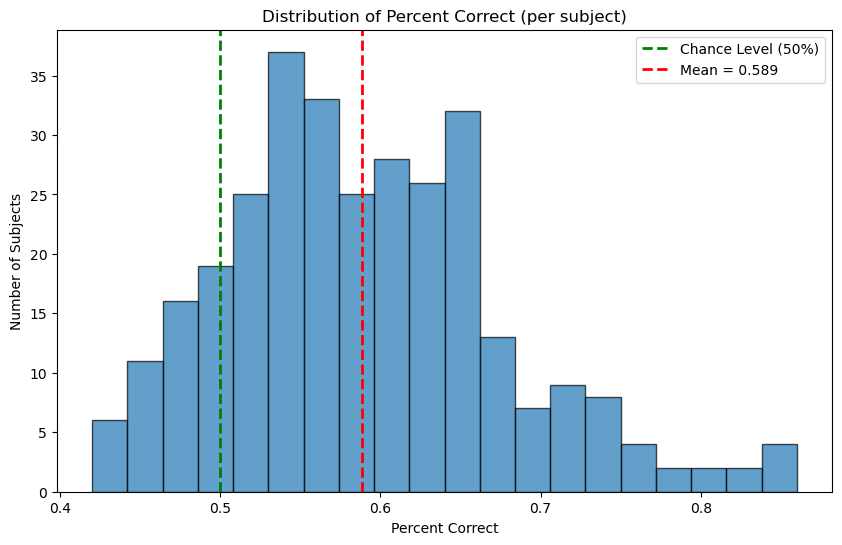

In [10]:
# Distribution of percent correct across subjects
plt.figure(figsize=(10, 6))
plt.hist(percent_cor_IDs['cor_ans'], bins=20, edgecolor="black", alpha=0.7)
plt.axvline(0.5, color='green', linestyle='dashed', linewidth=2, label='Chance Level (50%)')
plt.axvline(percent_cor_IDs['cor_ans'].mean(), color='red', 
            linestyle='dashed', linewidth=2, label=f'Mean = {percent_cor_IDs["cor_ans"].mean():.3f}')
plt.xlabel("Percent Correct")
plt.ylabel("Number of Subjects")
plt.title("Distribution of Percent Correct (per subject)")
plt.legend()
plt.show()

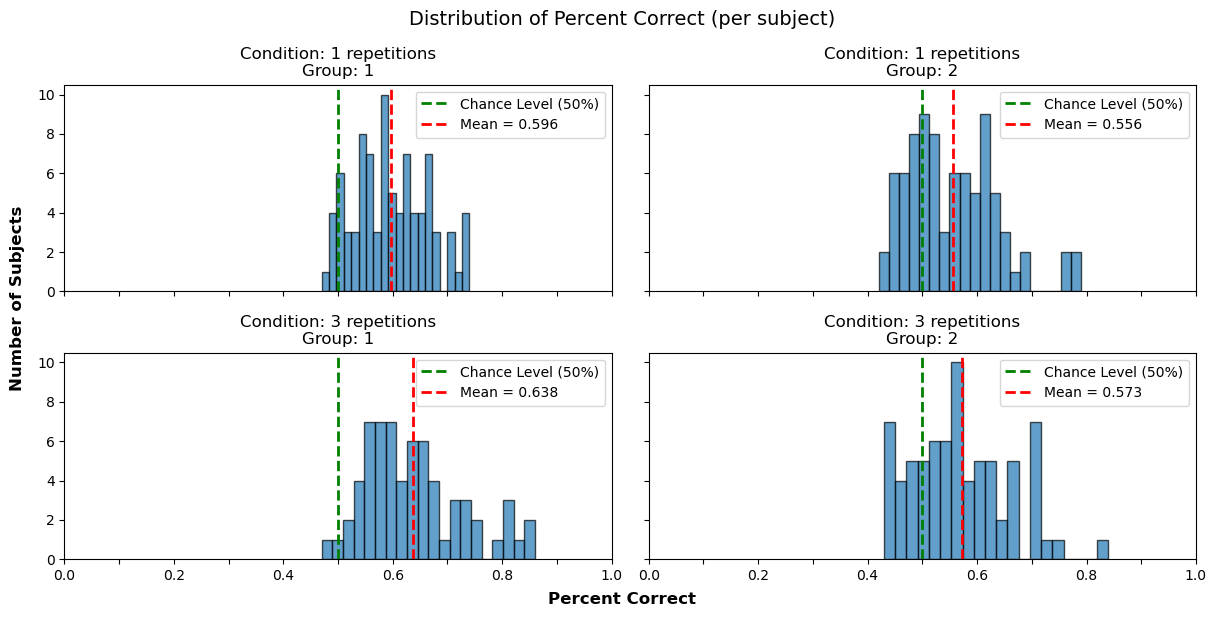

In [11]:
# Distribution of percent correct across subjects
# by groups
groups = np.tile(np.sort(percent_cor_IDs["group"].unique()), 2)
conds = np.repeat(
    np.sort(percent_cor_IDs["condition"].unique()), 
    2)
fig, axes = plt.subplots(2,2, # rows, cols
                         figsize=(12, 6), 
                         sharey=True,sharex=True # share x and y axis scales
                         )
axes = axes.ravel()

for ax, g, cond in zip(axes, groups, conds):
    data = percent_cor_IDs.loc[(percent_cor_IDs["group"] == g) & (percent_cor_IDs["condition"] == cond), "cor_ans"]
    ax.hist(data, bins=20, edgecolor="black", alpha=0.7)
    
    # Chance level
    ax.axvline(.50, color="green", linestyle="dashed", linewidth=2, label="Chance Level (50%)")
    # Group mean
    ax.axvline(data.mean(), color="red", linestyle="dashed", linewidth=2, label=f"Mean = {data.mean():.3f}")
    
    ax.set_title(f"Condition: {cond.split('_')[0]} repetitions\nGroup: {g[-1]}") # g = 'Group1' or 'Group2', so g[-1] is '1' or '2'
    ax.set_xlim(0,1)
    ax.set_xticks(np.arange(0, 1.1, 0.1))
    ax.set_xticklabels([f"{x:.1f}" if i % 2 == 0 else '' for i, x in enumerate(np.arange(0, 1.1, 0.1))])
    ax.legend()


fig.text(-0.01, 0.5, 'Number of Subjects', va='center', rotation='vertical', fontsize=12, fontweight='bold')
fig.text(0.5, -0.01, 'Percent Correct', ha='center', fontsize=12, fontweight='bold')
fig.suptitle("Distribution of Percent Correct (per subject)", fontsize=14)
plt.tight_layout()
plt.show()

# H & FA by subject

Calculate d' with adjustments (for both hits and false alarms Macmillan & Kaplan, 1985), so that if there is a perfect (1) or terrible (0) hit, or fa, we still got a value (not infinity):
$$\text{Hit} = \frac{N_{hits} + 0.5}{N_{signal\_trials} + 1}$$

Same for FAs.

In [12]:
# Compute hits and number of signal trials per subject
hits_IDs = (
    data_test
    .loc[data_test['item_type'] == 'Target']
    .groupby('subject_id', observed=True)
    .agg(
        hits=('cor_ans', 'sum'),
        signal_trials=('cor_ans', 'count')
    )
    .reset_index()
)

# Compute unadjusted hit rate
hits_IDs['Hit_rate'] = hits_IDs['hits'] / hits_IDs['signal_trials']

# Apply Macmillan & Kaplan (1985) correction
hits_IDs['Hit_rate_adj'] = (hits_IDs['hits'] + 0.5) / (hits_IDs['signal_trials'] + 1)
hits_IDs

,subject_id,hits,signal_trials,Hit_rate,Hit_rate_adj
0,90596,29,50,0.58,0.578431
1,90597,35,50,0.70,0.696078
2,90605,30,50,0.60,0.598039
3,90626,25,50,0.50,0.500000
4,90630,25,50,0.50,0.500000
...,...,...,...,...,...
304,93059,28,50,0.56,0.558824
305,93067,36,50,0.72,0.715686
306,93073,28,50,0.56,0.558824
307,93082,34,50,0.68,0.676471


In [13]:
# Compute false alarms and number of noise trials per subject
fa_IDs = (
    data_test
    .loc[data_test['item_type'] == 'Foil']
    .groupby('subject_id', observed=True)
    .agg(
        # Count "l" responses as false alarms
        FA=('response', lambda x: (x == 'l').sum()),
        noise_trials=('response', 'count')
    )
    .reset_index()
)

# Compute unadjusted false alarm rate
fa_IDs['FA_rate'] = fa_IDs['FA'] / fa_IDs['noise_trials']

# Apply Macmillan & Kaplan (1985) correction
fa_IDs['FA_rate_adj'] = (fa_IDs['FA'] + 0.5) / (fa_IDs['noise_trials'] + 1)

fa_IDs

,subject_id,FA,noise_trials,FA_rate,FA_rate_adj
0,90596,31,50,0.62,0.617647
1,90597,27,50,0.54,0.539216
2,90605,16,50,0.32,0.323529
3,90626,26,50,0.52,0.519608
4,90630,26,50,0.52,0.519608
...,...,...,...,...,...
304,93059,21,50,0.42,0.421569
305,93067,30,50,0.60,0.598039
306,93073,18,50,0.36,0.362745
307,93082,19,50,0.38,0.382353


In [14]:
# Calculate d'
dprime_ID = pd.merge(hits_IDs, fa_IDs, on='subject_id')
dprime_ID['dprimes'] = [stats.norm.ppf(hit) - stats.norm.ppf( (fa) ) 
  for hit, fa 
  in zip(dprime_ID['Hit_rate_adj'], dprime_ID['FA_rate_adj'])
  ]

# Drop columns
dprime_ID = (dprime_ID
 .drop( columns={'hits', 'signal_trials', 'Hit_rate', 'FA', 'noise_trials', 'FA_rate'})
 .rename(columns = {'Hit_rate_adj':'Hit_rate',
                    'FA_rate_adj':'FA_rate'})
 )

# Add groups and conditions from percent_cor_IDs
dprime_ID = pd.merge(
    dprime_ID, 
    percent_cor_IDs[['subject_id','group','condition']], 
    on='subject_id'
    )

dprime_ID

,subject_id,Hit_rate,FA_rate,dprimes,group,condition
0,90596,0.578431,0.617647,-0.101425,Group2,1_Rep
1,90597,0.696078,0.539216,0.414697,Group1,1_Rep
2,90605,0.598039,0.323529,0.706127,Group1,3_Rep
3,90626,0.500000,0.519608,-0.049169,Group1,1_Rep
4,90630,0.500000,0.519608,-0.049169,Group2,1_Rep
...,...,...,...,...,...,...
304,93059,0.558824,0.421569,0.345869,Group1,3_Rep
305,93067,0.715686,0.598039,0.321799,Group1,3_Rep
306,93073,0.558824,0.362745,0.499118,Group2,1_Rep
307,93082,0.676471,0.382353,0.757159,Group2,1_Rep


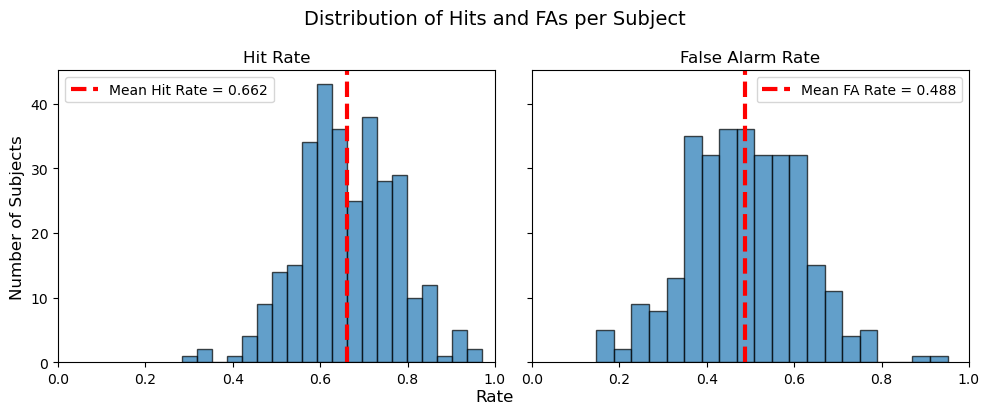

In [15]:
# Hits and FAs distribution (before filtering!)
fig, axes = plt.subplots(1, 2, # rows, cols
                         figsize=(10, 4), 
                         sharey=True,sharex=True # share x and y axis scales
                         )


axes[0].hist(dprime_ID['Hit_rate'], bins=20, edgecolor="black", alpha=0.7)
axes[1].hist(dprime_ID['FA_rate'], bins=20, edgecolor="black", alpha=0.7)

axes[0].set_xlim(0, 1)

# Mean
axes[0].axvline(dprime_ID['Hit_rate'].mean(), color="red", 
                linestyle="dashed", linewidth=3, 
                label=f"Mean Hit Rate = {dprime_ID['Hit_rate'].mean():.3f}")
axes[1].axvline(dprime_ID['FA_rate'].mean(), color="red", 
                linestyle="dashed", linewidth=3, 
                label=f"Mean FA Rate = {dprime_ID['FA_rate'].mean():.3f}")

axes[0].set_title("Hit Rate")
axes[1].set_title("False Alarm Rate") 

fig.text(0.5, 0, "Rate", ha="center", fontsize=12)

axes[0].legend()
axes[1].legend()

axes[0].set_ylabel("Number of Subjects", fontsize=12)
fig.suptitle("Distribution of Hits and FAs per Subject", fontsize=14)
plt.tight_layout()
plt.show()

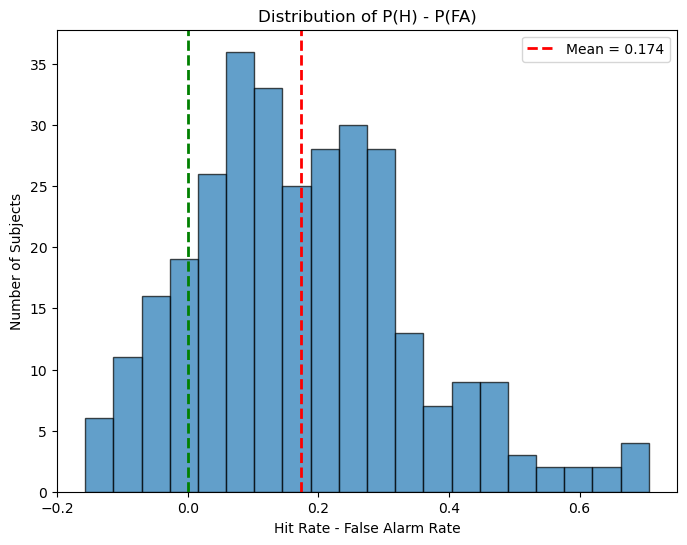

In [16]:
# p(H) - p(FA)
plt.figure(figsize=(8, 6))
plt.hist(dprime_ID['Hit_rate'] - dprime_ID['FA_rate'], bins=20, edgecolor="black", alpha=0.7)
plt.axvline(0, color='green', linestyle='dashed', linewidth=2)
plt.axvline((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']).mean(), 
            color='red', linestyle='dashed', linewidth=2,
            label=f'Mean = {(dprime_ID["Hit_rate"] - dprime_ID["FA_rate"]).mean():.3f}')
plt.xlabel("Hit Rate - False Alarm Rate")
plt.ylabel("Number of Subjects")
plt.title("Distribution of P(H) - P(FA)")
plt.legend()
plt.show()

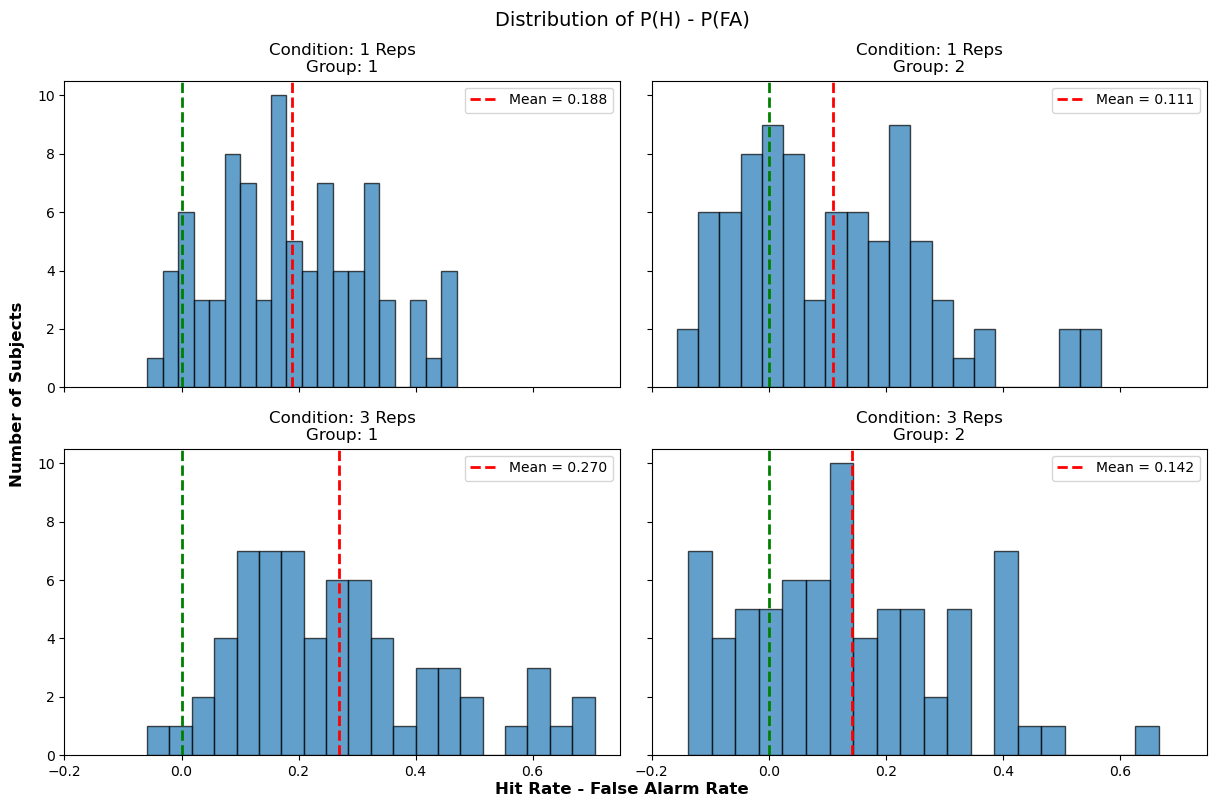

In [17]:
# p(H) - p(FA) plot by group and condition (before filtering!)
groups = np.tile(np.sort(dprime_ID['group'].unique()), 2)
conds = np.repeat(np.sort(dprime_ID['condition'].unique()), 2)

fig, axes = plt.subplots(2, 2, # rows, cols
                         figsize=(12, 8),
                         sharex=True, sharey=True # share x and y axis scales
                         )
axes = axes.ravel()
for ax, g, cond in zip(axes, groups, conds):
    data = (
        dprime_ID.loc[(dprime_ID['group'] == g) & (dprime_ID['condition'] == cond), 'Hit_rate'] - 
        dprime_ID.loc[(dprime_ID['group'] == g) & (dprime_ID['condition'] == cond), 'FA_rate']
        )
    ax.hist(data, bins=20, edgecolor="black", alpha=0.7)
    
    # Chance level
    ax.axvline(0, color='green', linestyle='dashed', linewidth=2)
    # Group & Condition mean
    ax.axvline(data.mean(), color='red', linestyle='dashed', linewidth=2,
               label=f'Mean = {data.mean():.3f}')
    
    ax.set_title(f"Condition: {cond[0]} Reps\nGroup: {g[-1]}") # g = 'Group1' or 'Group2', so g[-1] is '1' or '2'
    ax.legend()

fig.text(0.5, 0, "Hit Rate - False Alarm Rate", ha="center", fontsize=12, fontweight='bold')
fig.text(-0.01, 0.5, 'Number of Subjects', va='center', rotation='vertical', fontsize=12, fontweight='bold')
fig.suptitle("Distribution of P(H) - P(FA)", fontsize=14)
plt.tight_layout()
plt.show()

## Filter out subjects 

We filter out subjects based on (Hit - FA) threshold

In [18]:
# Conditional thresholds for both conditions and groups
threshold_by_cond = (
    (dprime_ID['Hit_rate'] - dprime_ID['FA_rate'])
    .groupby([dprime_ID['condition'], dprime_ID['group']], observed=True)
    .quantile(0.25) # top 75% of subjects in each condition/group
)
threshold_by_cond = np.maximum(threshold_by_cond,0) # make sure thresholds are not negative

# thresholds are:
print(f'Thresholds are:')
for idx, val in threshold_by_cond.items():
    print(f'  {idx}: {val:.3f}')

conditions = [
    (dprime_ID['condition'] == '1_Rep') & (dprime_ID['group'] == 'Group1') &
    ((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']) >= threshold_by_cond[('1_Rep','Group1')]),
    
    (dprime_ID['condition'] == '1_Rep') & (dprime_ID['group'] == 'Group2') &
    ((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']) >= threshold_by_cond[('1_Rep','Group2')]),
    
    (dprime_ID['condition'] == '3_Rep') & (dprime_ID['group'] == 'Group1') &
    ((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']) >= threshold_by_cond[('3_Rep','Group1')]),
    
    (dprime_ID['condition'] == '3_Rep') & (dprime_ID['group'] == 'Group2') &
    ((dprime_ID['Hit_rate'] - dprime_ID['FA_rate']) >= threshold_by_cond[('3_Rep','Group2')]),
]
choices = [True, True, True, True] # conditions for good subjects, so default is False (next line)

dprime_ID['good_subj'] = np.select(conditions, choices, default=False)
bad_subjects = dprime_ID.loc[dprime_ID['good_subj'] == False,'subject_id'].tolist()

Thresholds are:
  ('1_Rep', 'Group1'): 0.088
  ('1_Rep', 'Group2'): 0.000
  ('3_Rep', 'Group1'): 0.137
  ('3_Rep', 'Group2'): 0.020


In [19]:
# Add column good_subj (filter by Hit - FA)
data_test = (pd.merge(data_test, 
                               dprime_ID.loc[:,['subject_id','good_subj']], 
                               on='subject_id')
                      )
data_memory = (pd.merge(data_memory, 
                               dprime_ID.loc[:,['subject_id','good_subj']], 
                               on='subject_id')
                      )

In [20]:
# save filtered data
filtered_data_test = data_test[data_test['good_subj'] == True].copy().reset_index(drop=True)
filtered_data_memory = data_memory[data_memory['good_subj'] == True].copy().reset_index(drop=True)

In [21]:
# N good subjects
(filtered_data_test
 .groupby(['condition','group'], observed=True)['subject_id']
 .nunique()
 .reset_index(name='N_subj')
 )

,condition,group,N_subj
0,1_Rep,Group1,65
1,1_Rep,Group2,61
2,3_Rep,Group1,50
3,3_Rep,Group2,56


In [22]:
# Total N good subjects
print(f"Total number of good subjects: {filtered_data_test['subject_id'].nunique()}")
print(f"Total number of all subjects: {data_test['subject_id'].nunique()}")
print(f"Proportion of good subjects: {filtered_data_test['subject_id'].nunique() / data_test['subject_id'].nunique():.3f}")

Total number of good subjects: 232
Total number of all subjects: 309
Proportion of good subjects: 0.751


# ANOVA: item-level

In [30]:
# Proportion Yes by image_id
df_by_item = (filtered_data_test
            .groupby(
                ['image_id','condition','group','item_type','set',
                 'distinct_type','distinct_rating','category_name'], 
                observed=True)
            .agg(n_subj=('cor_ans', 'size'),
                n_yes=('response', lambda x: (x == "l").sum()),
                )
            .reset_index()
            .assign(prop_yes=lambda df: (df['n_yes']+0.5) / (df['n_subj']+1), # Apply Macmillan & Kaplan (1985) correction
                    resp_type = lambda df: np.where(df['item_type'] == 'Target', 'Hit', 'FA')
                    )
            )
df_by_item

,image_id,condition,group,item_type,set,distinct_type,distinct_rating,category_name,n_subj,n_yes,prop_yes,resp_type
0,3,1_Rep,Group1,Foil,B,Bottom,3.17,Andesite,65,20,0.310606,FA
1,3,1_Rep,Group2,Target,B,Bottom,3.17,Andesite,61,32,0.524194,Hit
2,3,3_Rep,Group1,Foil,B,Bottom,3.17,Andesite,50,14,0.284314,FA
3,3,3_Rep,Group2,Target,B,Bottom,3.17,Andesite,56,28,0.500000,Hit
4,4,1_Rep,Group1,Foil,B,Bottom,3.18,Andesite,65,37,0.568182,FA
...,...,...,...,...,...,...,...,...,...,...,...,...
395,472,3_Rep,Group2,Foil,A,Bottom,2.55,Shale,56,14,0.254386,FA
396,476,1_Rep,Group1,Target,A,Bottom,2.48,Shale,65,46,0.704545,Hit
397,476,1_Rep,Group2,Foil,A,Bottom,2.48,Shale,61,32,0.524194,FA
398,476,3_Rep,Group1,Target,A,Bottom,2.48,Shale,50,40,0.794118,Hit


In [83]:
# Wide format
# Separate columns for Hit and FA
df_by_item_wide = df_by_item.pivot_table(
    index=['image_id','condition','set','distinct_type','distinct_rating','category_name'],
    columns='resp_type',
    values='prop_yes'
).reset_index()
df_by_item_wide

resp_type,image_id,condition,set,distinct_type,distinct_rating,category_name,FA,Hit
0,3,1_Rep,B,Bottom,3.17,Andesite,0.310606,0.524194
1,3,3_Rep,B,Bottom,3.17,Andesite,0.284314,0.500000
2,4,1_Rep,B,Bottom,3.18,Andesite,0.568182,0.556452
3,4,3_Rep,B,Bottom,3.18,Andesite,0.460784,0.447368
4,6,1_Rep,A,Bottom,3.17,Andesite,0.556452,0.734848
...,...,...,...,...,...,...,...,...
195,471,3_Rep,B,Bottom,2.73,Shale,0.421569,0.675439
196,472,1_Rep,A,Bottom,2.55,Shale,0.362903,0.598485
197,472,3_Rep,A,Bottom,2.55,Shale,0.254386,0.480392
198,476,1_Rep,A,Bottom,2.48,Shale,0.524194,0.704545


## Hits

In [84]:
# Linear regression
m_hits = smf.ols(
    "Hit ~ condition * distinct_type * set",
    data=df_by_item_wide
    ) \
    .fit(cov_type='HC3') # hc3 - heteroscedasticity-corrected coefficient covariance matrix

anova_lm(m_hits, typ = 2).round(3) # ANOVA table with type II sums of squares

,sum_sq,df,F,PR(>F)
condition,0.120,1.0,10.129,0.002
distinct_type,0.128,1.0,10.811,0.001
set,0.044,1.0,3.753,0.054
condition:distinct_type,0.080,1.0,6.798,0.010
condition:set,0.000,1.0,0.038,0.846
distinct_type:set,0.007,1.0,0.556,0.457
condition:distinct_type:set,0.002,1.0,0.181,0.671
Residual,2.273,192.0,NaN,NaN


In [85]:
# LM-like summary
print(m_hits.summary())

                            OLS Regression Results                            
Dep. Variable:                    Hit   R-squared:                       0.117
Model:                            OLS   Adj. R-squared:                  0.085
Method:                 Least Squares   F-statistic:                     5.744
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           4.75e-06
Time:                        13:44:18   Log-Likelihood:                 163.95
No. Observations:                 200   AIC:                            -311.9
Df Residuals:                     192   BIC:                            -285.5
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                                                       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------

## FA

In [86]:
# Linear regression
m_fa = smf.ols(
    "FA ~ condition * distinct_type * set",
    data=df_by_item_wide
    ) \
    .fit(cov_type='HC3') # hc3 - heteroscedasticity-corrected coefficient covariance matrix

anova_lm(m_fa, typ = 2).round(3) # ANOVA table with type II sums of squares

,sum_sq,df,F,PR(>F)
condition,0.000,1.0,0.008,0.928
distinct_type,8.226,1.0,435.512,0.000
set,0.208,1.0,10.990,0.001
condition:distinct_type,0.016,1.0,0.848,0.358
condition:set,0.043,1.0,2.253,0.135
distinct_type:set,0.004,1.0,0.203,0.653
condition:distinct_type:set,0.003,1.0,0.137,0.712
Residual,3.626,192.0,NaN,NaN


In [87]:
# LM-like summary
print(m_fa.summary())

                            OLS Regression Results                            
Dep. Variable:                     FA   R-squared:                       0.515
Model:                            OLS   Adj. R-squared:                  0.498
Method:                 Least Squares   F-statistic:                     63.79
Date:                Fri, 02 Oct 2026   Prob (F-statistic):           9.34e-47
Time:                        13:44:20   Log-Likelihood:                 117.22
No. Observations:                 200   AIC:                            -218.4
Df Residuals:                     192   BIC:                            -192.1
Df Model:                           7                                         
Covariance Type:                  HC3                                         
                                                       coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------

## Post-hoc 

**Post-hoc Comparisons**

Contrasts (separate models for Hits and FAs; low distinctive = `Bottom`, high distinctive = `Top`; each contrast is averaged over `set`):

- For Hits:
    * 1 vs 3 (low)
    * 1 vs 3 (high)
    * low vs high (1)
    * low vs high (3)

- Similarly for FAs:
    * 1 vs 3 (low)
    * 1 vs 3 (high)
    * low vs high (1)
    * low vs high (3)

**Model**

Each model is a full factorial OLS regression, `DV ~ condition * distinct_type * set`, with $2 \times 2 \times 2 = 8$ cells and $p = 8$ coefficients $\hat{\beta}$. Because the model is saturated, the predicted value for each cell equals that cell's observed mean $\bar{y}_k$.

**Contrast estimate**

Each contrast is a set of weights $c_k$ over the 8 cells ($k = 1, \dots, 8$), with $\sum_k c_k = 0$. Averaging over `set` means each condition × distinct_type combination gets weight $\pm 0.5$ in set A and $\pm 0.5$ in set B. For example, for 1 vs 3 (low):

$$c_{1\_Rep,\,Bottom,\,A} = c_{1\_Rep,\,Bottom,\,B} = +0.5, \quad c_{3\_Rep,\,Bottom,\,A} = c_{3\_Rep,\,Bottom,\,B} = -0.5, \quad \text{all others } 0$$

The cell weights are mapped onto the model coefficients through the design rows of the cells, $x_k$ (one row of the design matrix per cell):

$$L = \sum_k c_k \, x_k, \qquad \hat{\psi} = L \hat{\beta} = \sum_k c_k \, \bar{y}_k$$

**Standard error (HC3 robust covariance)**

Different variances across groups are handled by the heteroscedasticity-consistent covariance matrix HC3 instead of a pooled MSE:

$$\hat{V}_{HC3} = (X^\top X)^{-1} \, X^\top \, \mathrm{diag}\!\left(\frac{e_i^2}{(1 - h_{ii})^2}\right) X \, (X^\top X)^{-1}$$

where $e_i$ is the residual of observation $i$ and $h_{ii} = x_i (X^\top X)^{-1} x_i^\top$ is its leverage. Then:

$$SE = \sqrt{L \, \hat{V}_{HC3} \, L^\top}$$

In a saturated cell-means model, every observation in cell $k$ has leverage $h_{ii} = 1/n_k$, so the formula reduces to:

$$SE = \sqrt{\sum_k \frac{c_k^2 \, s_k^2}{n_k - 1}}$$

where $s_k^2$ is the sample variance of cell $k$. This is the same as the Welch SE, except it divides by $n_k - 1$ instead of $n_k$, which makes it slightly more conservative.

**Test statistic and p-value**

$$t = \frac{\hat{\psi}}{SE}, \qquad df = df_{residual} = N - p = N - 8$$

$$p = 2 \cdot P(T_{df} > |t|)$$

$N$ is the number of rows used to fit the model (`model.df_resid` gives $df$ directly).

**Multiple-comparison correction (Bonferroni across all 8 contrasts, Hits + FAs)**

$$p_{adj} = \min(8 \cdot p, \; 1)$$

In [88]:
# Planned contrasts on cell means of a fitted statsmodels formula model,
# using the model's own covariance matrix (HC3 if fit with cov_type='HC3')
# contrasts : {name: [(cell_dict, weight), ...]}
# use_t : True -> t distribution with df_resid; False -> normal (statsmodels' default for robust cov)

def planned_contrasts(model, data, contrasts, factors,
                      p_adjust='bonferroni', use_t=True):
    design_info = model.model.data.design_info
    beta = model.params.values
    V = model.cov_params().values          # robust (HC3) cov if the model was fit that way
    df_resid = model.df_resid
    existing_cells = data[factors].drop_duplicates()

    rows = []
    for name, terms in contrasts.items():
        cells = pd.DataFrame([c for c, _ in terms])[factors]
        w = np.array([wt for _, wt in terms], dtype=float)

        # --- checks ---
        if not np.isclose(w.sum(), 0):
            raise ValueError(f"'{name}': weights sum to {w.sum()}, not 0")
        found = cells.merge(existing_cells, on=factors, how='left', indicator=True)
        if (found['_merge'] != 'both').any():
            bad = cells[(found['_merge'] != 'both').values]
            raise ValueError(f"'{name}': cell(s) not in data:\n{bad}")

        # --- contrast ---
        X = np.asarray(dmatrix(design_info, cells, return_type='dataframe'))
        L = w @ X
        est = L @ beta
        se = np.sqrt(L @ V @ L)
        stat = est / se
        p = 2 * (stats.t.sf(abs(stat), df_resid) if use_t else stats.norm.sf(abs(stat)))

        # sanity check: raw mean difference (should equal est for a full-factorial model)
        raw_means = cells.merge(
            data.groupby(factors, observed=True)[model.model.endog_names].mean().reset_index(),
            on=factors, how='left')[model.model.endog_names].values
        raw_diff = w @ raw_means

        rows.append({'contrast': name, 'estimate': est, 'raw_diff': raw_diff,
                     'se': se, 't' if use_t else 'z': stat,
                     'df': df_resid if use_t else np.inf, 'p_value': p})

    res = pd.DataFrame(rows).set_index('contrast')
    if p_adjust:
        res['p_adjusted'] = multipletests(res['p_value'], method=p_adjust)[1]
        res['sig'] = pd.cut(res['p_adjusted'], [-np.inf, .001, .01, .05, np.inf],
                            labels=['***', '**', '*', ''], right=False)
    return res

In [89]:
factors = ['condition', 'distinct_type', 'set']
SETS = ['A', 'B']

# Cell (condition, distinct_type) averaged over set, scaled by weight.
def avg_over_set(condition, distinct_type, weight):
    return [({'condition': condition, 'distinct_type': distinct_type, 'set': s},
             weight / len(SETS)) for s in SETS]

contrasts = {
    'Bottom: 1_Rep vs 3_Rep':
        avg_over_set('1_Rep', 'Bottom', 1) + avg_over_set('3_Rep', 'Bottom', -1),
    'Top: 1_Rep vs 3_Rep':
        avg_over_set('1_Rep', 'Top', 1)    + avg_over_set('3_Rep', 'Top', -1),
    'Bottom vs Top (1_Rep)':
        avg_over_set('1_Rep', 'Bottom', 1) + avg_over_set('1_Rep', 'Top', -1),
    'Bottom vs Top (3_Rep)':
        avg_over_set('3_Rep', 'Bottom', 1) + avg_over_set('3_Rep', 'Top', -1),
}

In [90]:
# Unadjusted p-values per model, then Bonferroni across all 8
res_hits = planned_contrasts(m_hits, df_by_item_wide, contrasts, factors, p_adjust=None)
res_fa = planned_contrasts(m_fa,   df_by_item_wide, contrasts, factors, p_adjust=None)

posthoc = pd.concat({'Hits': res_hits, 'FAs': res_fa}, names=['model', 'contrast'])
posthoc['p_adjusted'] = multipletests(posthoc['p_value'], method='bonferroni')[1]
posthoc['sig'] = pd.cut(posthoc['p_adjusted'], [-np.inf, .001, .01, .05, np.inf],
                        labels=['***', '**', '*', ''], right=False)
posthoc.reset_index(inplace=True)
posthoc


,model,contrast,estimate,raw_diff,se,t,df,p_value,p_adjusted,sig
0,Hits,Bottom: 1_Rep vs 3_Rep,-0.030042,-0.030042,0.017332,-1.733379,192.0,8.463376e-02,6.770701e-01,
1,Hits,Top: 1_Rep vs 3_Rep,-0.134681,-0.134681,0.035925,-3.748937,192.0,2.349226e-04,1.879381e-03,**
2,Hits,Bottom vs Top (1_Rep),0.002960,0.002960,0.030942,0.095668,192.0,9.238844e-01,1.000000e+00,
3,Hits,Bottom vs Top (3_Rep),-0.101679,-0.101679,0.025171,-4.039560,192.0,7.738626e-05,6.190901e-04,***
4,FAs,Bottom: 1_Rep vs 3_Rep,0.018667,0.018667,0.022713,0.821893,192.0,4.121573e-01,1.000000e+00,
5,FAs,Top: 1_Rep vs 3_Rep,-0.016761,-0.016761,0.028369,-0.590839,192.0,5.553231e-01,1.000000e+00,
6,FAs,Bottom vs Top (1_Rep),0.382605,0.382605,0.023952,15.973789,192.0,4.287218e-37,3.429774e-36,***
7,FAs,Bottom vs Top (3_Rep),0.347176,0.347176,0.027330,12.702956,192.0,3.124309e-27,2.499447e-26,***


## Plot

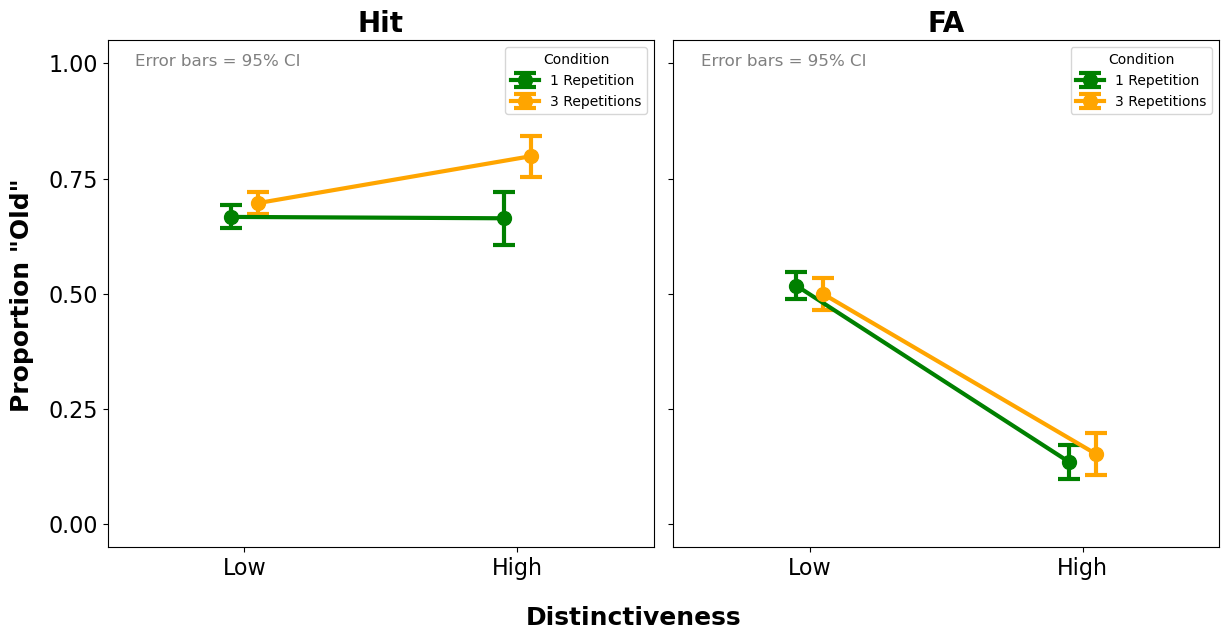

In [91]:
# Plot 
# Summary stats for plotting
summary = (
    df_by_item
    .groupby(["condition", "resp_type", "distinct_type"], observed=False)
    .agg(
        mean_prop=("prop_yes", "mean"),
        n=("prop_yes", "size"),
        sd=("prop_yes", "std")
    )
    .reset_index()
)
summary["se"] = summary["sd"] / np.sqrt(summary["n"])
summary["ci95"] = summary["se"] * stats.t.ppf(0.975, summary["n"] - 1)


fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)

resp_levels = ["Hit", "FA"]
conditions = sorted(df_by_item["condition"].unique())
x_levels = sorted(df_by_item["distinct_type"].unique())
x_pos = np.arange(len(x_levels))

# color
color_map = {
    "1_Rep": "green",
    "3_Rep": "orange"
}
condition_label_map = {
    "1_Rep": "1 Repetition",
    "3_Rep": "3 Repetitions"
}
# slighly to the left/right from the center of the x-ticks
offset_map = {
    "1_Rep": -0.05,
    "3_Rep":  0.05
}
x_label_map = {
    "Bottom": "Low",
    "Top": "High"
}

for ax, resp in zip(axes, resp_levels):

    for cond in conditions:
        summ = summary[
            (summary["resp_type"] == resp) &
            (summary["condition"] == cond)
        ]

        means = []
        cis = []

        for lvl in x_levels:
            row = summ[summ["distinct_type"] == lvl].iloc[0]
            means.append(row["mean_prop"])
            cis.append(row["ci95"])

        ax.errorbar(
            x_pos + offset_map[cond], # offset for visibility
            means,
            yerr=cis,
            fmt="o-", # o means draw the mean circle, - means connect with line
            capthick=3, # 
            capsize=8,
            linewidth=3,
            markersize=10,
            color=color_map[cond],
            label=condition_label_map[cond]
        )

    ax.set_title(resp, fontsize=20, fontweight="bold")
    ax.set_xticks(x_pos)
    ax.set_xticklabels([x_label_map[lvl] for lvl in x_levels], fontsize=16)
    ax.set_xlim(-0.5, len(x_levels) - 0.5)
    ax.set_ylim(-0.05, 1.05)
    ax.set_yticks(np.arange(0, 1.1, 0.25))
    ax.tick_params(axis="both", labelsize=16)
    ax.text(0.05, 0.95, f'Error bars = 95% CI', transform=ax.transAxes, fontsize=12, color='gray')
    ax.legend(title="Condition")

fig.text(-0.02, 0.5, 'Proportion "Old"', va="center",
         rotation="vertical", fontsize=18, fontweight="bold")
fig.text(0.5, -0.05, "Distinctiveness", ha="center",
         fontsize=18, fontweight="bold")

plt.tight_layout()
plt.show()

# Split-Half

In [66]:
# add response types to filtered_data_test
conditions = [
    (filtered_data_test['item_type'] == 'Target') & (filtered_data_test['cor_ans'] == True),
    (filtered_data_test['item_type'] == 'Target') & (filtered_data_test['cor_ans'] == False),
    (filtered_data_test['item_type'] == 'Foil') & (filtered_data_test['cor_ans'] == True),
    (filtered_data_test['item_type'] == 'Foil') & (filtered_data_test['cor_ans'] == False),
]

choices = ['Hit', 'Miss', 'CR', 'FA']

filtered_data_test['resp_type'] = np.select(conditions, choices, default=None)
filtered_data_test

,trial_index,subject_id,group,condition,task,item_type,response,correct_response,cor_ans,rt,category_name,category,broad_category,image_png,image_id,distinct_rating,distinct_type,set,good_subj,resp_type
0,311,91746,Group2,3_Rep,test_phase,Target,l,l,True,1776.0,Gneiss,13,M,M_Gneiss_15.png,207,3.11,Bottom,B,True,Hit
1,313,91746,Group2,3_Rep,test_phase,Target,l,l,True,767.0,Rock Salt,28,S,S_Rock Salt_13.png,445,7.58,Top,B,True,Hit
2,315,91746,Group2,3_Rep,test_phase,Target,l,l,True,779.0,Pegmatite,7,I,I_Pegmatite_03.png,99,7.24,Top,B,True,Hit
3,317,91746,Group2,3_Rep,test_phase,Target,l,l,True,805.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom,B,True,Hit
4,319,91746,Group2,3_Rep,test_phase,Foil,a,a,True,924.0,Rhyolite,10,I,I_Rhyolite_16.png,160,2.19,Bottom,A,True,CR
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23195,501,92625,Group2,3_Rep,test_phase,Foil,a,a,True,1088.0,Obsidian,6,I,I_Obsidian_05.png,85,7.32,Top,A,True,CR
23196,503,92625,Group2,3_Rep,test_phase,Target,l,l,True,815.0,Gneiss,13,M,M_Gneiss_10.png,202,3.09,Bottom,B,True,Hit
23197,505,92625,Group2,3_Rep,test_phase,Foil,l,a,False,1000.0,Marble,15,M,M_Marble_04.png,228,3.15,Bottom,A,True,FA
23198,507,92625,Group2,3_Rep,test_phase,Target,l,l,True,683.0,Gneiss,13,M,M_Gneiss_14.png,206,3.41,Bottom,B,True,Hit


In [67]:
# ---------- Hits data for split-half reliability analysis ----------

# ---------- 1 Rep ----------

# ---------- Group 1 ----------

sh_df_hits_1rep_gr1_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='1_Rep') & 
                            (filtered_data_test['group']=='Group1') & 
                            (filtered_data_test['item_type']=='Target'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_hits_1rep_gr1_long['is_hit'] = np.where(sh_df_hits_1rep_gr1_long['resp_type']=='Hit', 1, 0)  # is hit or miss
sh_df_hits_1rep_gr1_long = sh_df_hits_1rep_gr1_long[['subject_id', 'image_id', 'is_hit']]  
# pivot a table wider
sh_df_hits_1rep_gr1 = sh_df_hits_1rep_gr1_long.pivot(index='image_id', columns='subject_id', values='is_hit')


# ---------- Group 2 ----------

sh_df_hits_1rep_gr2_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='1_Rep') & 
                            (filtered_data_test['group']=='Group2') & 
                            (filtered_data_test['item_type']=='Target'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_hits_1rep_gr2_long['is_hit'] = np.where(sh_df_hits_1rep_gr2_long['resp_type']=='Hit', 1, 0)  
sh_df_hits_1rep_gr2_long = sh_df_hits_1rep_gr2_long[['subject_id', 'image_id', 'is_hit']]  
# pivot a table wider
sh_df_hits_1rep_gr2 = sh_df_hits_1rep_gr2_long.pivot(index='image_id', columns='subject_id', values='is_hit')


# ---------- 3 Rep ----------

# ---------- Group 1 ----------

sh_df_hits_3rep_gr1_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='3_Rep') & 
                            (filtered_data_test['group']=='Group1') & 
                            (filtered_data_test['item_type']=='Target'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_hits_3rep_gr1_long['is_hit'] = np.where(sh_df_hits_3rep_gr1_long['resp_type']=='Hit', 1, 0)  
sh_df_hits_3rep_gr1_long = sh_df_hits_3rep_gr1_long[['subject_id', 'image_id', 'is_hit']]  
# pivot a table wider
sh_df_hits_3rep_gr1 = sh_df_hits_3rep_gr1_long.pivot(index='image_id', columns='subject_id', values='is_hit')

# ---------- Group 2 ----------

sh_df_hits_3rep_gr2_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='3_Rep') & 
                            (filtered_data_test['group']=='Group2') & 
                            (filtered_data_test['item_type']=='Target'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_hits_3rep_gr2_long['is_hit'] = np.where(sh_df_hits_3rep_gr2_long['resp_type']=='Hit', 1, 0)  
sh_df_hits_3rep_gr2_long = sh_df_hits_3rep_gr2_long[['subject_id', 'image_id', 'is_hit']]  
# pivot a table wider
sh_df_hits_3rep_gr2 = sh_df_hits_3rep_gr2_long.pivot(index='image_id', columns='subject_id', values='is_hit')

In [68]:
# Example of resulting tables:
# rows - image_id, columns - subject_id, values - 1 for hit, 0 for miss
sh_df_hits_3rep_gr2.head(10)

subject_id,91746,92208,91155,90707,91388,90950,92523,91224,91916,92252,...,90838,92458,91551,91813,92629,90680,91557,90645,91955,92625
image_id,,,,,,,,,,,,,,,,,,,,,
3,0,1,0,1,1,1,0,0,1,0,...,0,1,0,1,0,1,1,1,0,0
4,1,1,0,1,1,0,1,1,0,0,...,0,1,0,0,1,0,1,0,0,1
9,1,1,1,1,1,1,1,1,1,1,...,1,1,0,0,1,1,1,0,1,1
24,1,0,1,0,1,1,1,1,0,0,...,1,1,1,0,1,1,1,1,0,1
26,0,1,1,1,1,1,0,1,1,0,...,1,1,0,1,0,0,1,1,1,1
29,0,1,1,1,0,1,1,1,1,1,...,1,1,1,1,0,1,0,1,1,0
33,1,1,1,1,0,1,1,1,1,1,...,0,1,0,1,0,1,1,1,0,0
42,0,1,0,1,1,1,0,1,1,1,...,0,1,1,0,1,1,1,1,0,0
47,1,1,0,1,1,1,1,1,1,1,...,1,1,1,0,1,1,0,1,1,1


In [69]:
# ---------- FA data for split-half reliability analysis ----------


# ---------- 1 Rep ----------

# ---------- Group 1 ----------

sh_df_fa_1rep_gr1_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='1_Rep') & 
                            (filtered_data_test['group']=='Group1') & 
                            (filtered_data_test['item_type']=='Foil'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_fa_1rep_gr1_long['is_fa'] = np.where(sh_df_fa_1rep_gr1_long['resp_type']=='FA', 1, 0)  # is fa or cr
sh_df_fa_1rep_gr1_long
sh_df_fa_1rep_gr1_long = sh_df_fa_1rep_gr1_long[['subject_id', 'image_id', 'is_fa']]  
# # pivot a table wider
sh_df_fa_1rep_gr1 = sh_df_fa_1rep_gr1_long.pivot(index='image_id', columns='subject_id', values='is_fa')


# ---------- Group 2 ----------

sh_df_fa_1rep_gr2_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='1_Rep') & 
                            (filtered_data_test['group']=='Group2') & 
                            (filtered_data_test['item_type']=='Foil'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_fa_1rep_gr2_long['is_fa'] = np.where(sh_df_fa_1rep_gr2_long['resp_type']=='FA', 1, 0)  
sh_df_fa_1rep_gr2_long = sh_df_fa_1rep_gr2_long[['subject_id', 'image_id', 'is_fa']]  
# pivot a table wider
sh_df_fa_1rep_gr2 = sh_df_fa_1rep_gr2_long.pivot(index='image_id', columns='subject_id', values='is_fa')


# ---------- 3 Rep ----------

# ---------- Group 1 ----------

sh_df_fa_3rep_gr1_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='3_Rep') & 
                            (filtered_data_test['group']=='Group1') & 
                            (filtered_data_test['item_type']=='Foil'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_fa_3rep_gr1_long['is_fa'] = np.where(sh_df_fa_3rep_gr1_long['resp_type']=='FA', 1, 0)  # is fa or cr
sh_df_fa_3rep_gr1_long
sh_df_fa_3rep_gr1_long = sh_df_fa_3rep_gr1_long[['subject_id', 'image_id', 'is_fa']]  
# # pivot a table wider
sh_df_fa_3rep_gr1 = sh_df_fa_3rep_gr1_long.pivot(index='image_id', columns='subject_id', values='is_fa')


# ---------- Group 2 ----------

sh_df_fa_3rep_gr2_long = (
    (filtered_data_test.loc[(filtered_data_test['condition']=='3_Rep') & 
                            (filtered_data_test['group']=='Group2') & 
                            (filtered_data_test['item_type']=='Foil'), 
                            ['subject_id','condition','group','image_id','resp_type', 'item_type']])
    .copy()
    )
sh_df_fa_3rep_gr2_long['is_fa'] = np.where(sh_df_fa_3rep_gr2_long['resp_type']=='FA', 1, 0)  
sh_df_fa_3rep_gr2_long = sh_df_fa_3rep_gr2_long[['subject_id', 'image_id', 'is_fa']]  
# pivot a table wider
sh_df_fa_3rep_gr2 = sh_df_fa_3rep_gr2_long.pivot(index='image_id', columns='subject_id', values='is_fa')

In [70]:
# Example of resulting tables:
# rows - image_id, columns - subject_id, values - 1 for FA, 0 for CR
sh_df_fa_3rep_gr2.head(10)

subject_id,91746,92208,91155,90707,91388,90950,92523,91224,91916,92252,...,90838,92458,91551,91813,92629,90680,91557,90645,91955,92625
image_id,,,,,,,,,,,,,,,,,,,,,
6,1,0,1,1,0,0,0,0,0,1,...,0,0,1,0,1,0,1,0,1,1
8,0,1,1,0,0,1,1,1,1,1,...,0,1,1,1,1,1,1,0,1,0
10,0,1,1,0,1,1,1,1,1,0,...,1,0,0,0,0,0,1,0,0,0
17,1,1,0,0,1,1,1,1,0,1,...,1,1,0,1,0,1,1,1,1,1
18,0,1,0,1,0,1,1,1,1,0,...,0,1,0,0,1,1,1,1,1,1
25,1,1,1,1,0,1,0,0,1,1,...,1,0,1,0,0,0,1,0,1,0
35,0,1,0,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,0,1
36,0,1,1,1,0,1,1,1,1,1,...,1,1,0,0,1,1,1,1,0,1
37,0,1,1,1,1,1,1,1,0,1,...,0,1,1,1,1,1,1,1,1,1


In [71]:
# Store everything together
split_half_hits_dict = {
    "1_Rep": {
        "Group1": sh_df_hits_1rep_gr1,
        "Group2": sh_df_hits_1rep_gr2
    },
    "3_Rep": {
        "Group1": sh_df_hits_3rep_gr1,
        "Group2": sh_df_hits_3rep_gr2
    }
}

split_half_fa_dict = {
    "1_Rep": {
        "Group1": sh_df_fa_1rep_gr1,
        "Group2": sh_df_fa_1rep_gr2
    },
    "3_Rep": {
        "Group1": sh_df_fa_3rep_gr1,
        "Group2": sh_df_fa_3rep_gr2
    }
}

In [72]:
# function to compute split-half reliability

def split_half_reliability(df_gr1, df_gr2, n_iterations=10000, seed=1, is_random=False, print_idx=1000):
    
    np.random.seed(seed)
    corrs = []
    print('Iteration: ', end="")
    
    for i in range(n_iterations):
        
        if i % print_idx == 0:
            print(i, end=", ")
        elif i == n_iterations - 1:
            print("Finished!")
        
        # ----- Group 1 -----
        shuffled_cols_1 = np.random.permutation(df_gr1.columns)
        shuffled_df_1 = df_gr1[shuffled_cols_1]
        
        mid_1 = len(shuffled_df_1.columns) // 2
        first_half_1 = shuffled_df_1.iloc[:, :mid_1]
        second_half_1 = shuffled_df_1.iloc[:, mid_1:]
        
        mean_first_1 = first_half_1.mean(axis=1)
        mean_second_1 = second_half_1.mean(axis=1)
        
        # ----- Group 2 -----
        shuffled_cols_2 = np.random.permutation(df_gr2.columns)
        shuffled_df_2 = df_gr2[shuffled_cols_2]
        
        mid_2 = len(shuffled_df_2.columns) // 2
        first_half_2 = shuffled_df_2.iloc[:, :mid_2]
        second_half_2 = shuffled_df_2.iloc[:, mid_2:]
        
        mean_first_2 = first_half_2.mean(axis=1)
        mean_second_2 = second_half_2.mean(axis=1)
        
        # ----- Combine -----
        mean_first = pd.concat([mean_first_1, mean_first_2])
        mean_second = pd.concat([mean_second_1, mean_second_2])
        
        if is_random:
            # Shuffle the second half to get a null distribution
            mean_second = np.random.permutation(mean_second.values)
        
        # Spearman correlation + Spearman-Brown correction
        r, _ = stats.spearmanr(mean_first, mean_second)
        sb = (2 * r) / (1 + r)
        
        corrs.append(sb)
        
    return np.array(corrs)

In [73]:
# function to compute split-half reliability across conditions

def split_half_reliability_across_conditions(df_gr1_cond_A, df_gr1_cond_B,
                                             df_gr2_cond_A, df_gr2_cond_B,
                                             n_iterations=10000, seed=1, is_random=False, print_idx=1000):
    
    np.random.seed(seed)
    corrs = []
    print('Iteration: ', end="")
    
    # Mid-points
    mid_1_A = len(df_gr1_cond_A.columns) // 2
    mid_1_B = len(df_gr1_cond_B.columns) // 2
    mid_2_A = len(df_gr2_cond_A.columns) // 2
    mid_2_B = len(df_gr2_cond_B.columns) // 2
    
    for i in range(n_iterations):
        
        if i % print_idx == 0:
            print(i, end=", ")
        elif i == n_iterations - 1:
            print("Finished!")
        
        # ----- Group 1 -----
        
        # shuffle group 1 cond A
        shuffled_cols_1_A = np.random.permutation(df_gr1_cond_A.columns)
        shuffled_df_1_A = df_gr1_cond_A[shuffled_cols_1_A]
        # shuffle group 1 cond B
        shuffled_cols_1_B = np.random.permutation(df_gr1_cond_B.columns)
        shuffled_df_1_B = df_gr1_cond_B[shuffled_cols_1_B]
        
        # get half of all the values from cond A and half from cond B
        first_half_1_A = shuffled_df_1_A.iloc[:, :mid_1_A]
        second_half_1_B = shuffled_df_1_B.iloc[:, :mid_1_B]
        
        # calculate means for each half
        mean_first_1 = first_half_1_A.mean(axis=1)
        mean_second_1 = second_half_1_B.mean(axis=1)
        
        # ----- Group 2 -----
        # same as above but for group 2
        shuffled_cols_2_A = np.random.permutation(df_gr2_cond_A.columns)
        shuffled_df_2_A = df_gr2_cond_A[shuffled_cols_2_A]
        shuffled_cols_2_B = np.random.permutation(df_gr2_cond_B.columns)
        shuffled_df_2_B = df_gr2_cond_B[shuffled_cols_2_B]

        first_half_2_A = shuffled_df_2_A.iloc[:, :mid_2_A]
        second_half_2_B = shuffled_df_2_B.iloc[:, :mid_2_B]

        mean_first_2 = first_half_2_A.mean(axis=1)
        mean_second_2 = second_half_2_B.mean(axis=1)

        # ----- Combine -----
        mean_first = pd.concat([mean_first_1, mean_first_2])
        mean_second = pd.concat([mean_second_1, mean_second_2])
        
        if is_random:
            # Shuffle the second half to get a null distribution
            mean_second = np.random.permutation(mean_second.values)
        
        # Spearman correlation + Spearman-Brown correction
        r, _ = stats.spearmanr(mean_first, mean_second)
        sb = (2 * r) / (1 + r)
        
        corrs.append(sb)
        
    return np.array(corrs)

In [74]:
# Run split-half reliability analysis
sh_corrs_hits = {'Exact': {}, 'Random': {}}
sh_corrs_fa = {'Exact': {}, 'Random': {}}
N_iter = 10**4

for cond in split_half_hits_dict:
    
    df_gr1 = split_half_hits_dict[cond]["Group1"]
    df_gr2 = split_half_hits_dict[cond]["Group2"]
    
    print(f"\nRunning Hits split-half for {cond} - Exact")
    sh_corrs_hits['Exact'][cond] = split_half_reliability(df_gr1, df_gr2, 
                                                 n_iterations=N_iter, seed=12345, is_random=False)
    
    print(f"\nRunning Hits split-half for {cond} - Random")
    sh_corrs_hits['Random'][cond] = split_half_reliability(df_gr1, df_gr2, 
                                                       n_iterations=N_iter, seed=12345, is_random=True)

for cond in split_half_fa_dict:
    
    df_gr1 = split_half_fa_dict[cond]["Group1"]
    df_gr2 = split_half_fa_dict[cond]["Group2"]
    
    print(f"\nRunning FA split-half for {cond} - Exact")
    sh_corrs_fa['Exact'][cond] = split_half_reliability(df_gr1, df_gr2, 
                                                 n_iterations=N_iter, seed=12345, is_random=False)
    
    print(f"\nRunning FA split-half for {cond} - Random")
    sh_corrs_fa['Random'][cond] = split_half_reliability(df_gr1, df_gr2, 
                                                       n_iterations=N_iter, seed=12345, is_random=True)


Running Hits split-half for 1_Rep - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running Hits split-half for 1_Rep - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running Hits split-half for 3_Rep - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running Hits split-half for 3_Rep - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half for 1_Rep - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half for 1_Rep - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half for 3_Rep - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half for 3_Rep - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!


In [75]:
# Run split-half reliability analysis ACROSS conditions 
sh_corrs_hits_across = {'Exact': {}, 'Random': {}}
sh_corrs_fa_across = {'Exact': {}, 'Random': {}}
conditions = ["1_Rep", "3_Rep"]
N_iter = 10**4

# ========== Hits ==========
df_gr1_A = split_half_hits_dict[conditions[0]]["Group1"]
df_gr2_A = split_half_hits_dict[conditions[0]]["Group2"]

df_gr1_B = split_half_hits_dict[conditions[1]]["Group1"]
df_gr2_B = split_half_hits_dict[conditions[1]]["Group2"]

print(f"\nRunning Hits split-half - Exact")
sh_corrs_hits_across['Exact'] = split_half_reliability_across_conditions(df_gr1_A, df_gr2_A, 
                                                                        df_gr1_B, df_gr2_B,
                                                                        n_iterations=N_iter, 
                                                                        seed=12345, 
                                                                        is_random=False)

print(f"\nRunning Hits split-half - Random")
sh_corrs_hits_across['Random'] = split_half_reliability_across_conditions(df_gr1_A, df_gr2_A, 
                                                                          df_gr1_B, df_gr2_B,
                                                                          n_iterations=N_iter,
                                                                          seed=12345,
                                                                          is_random=True)

# ========== FA ==========
df_gr1_A = split_half_fa_dict[conditions[0]]["Group1"]
df_gr2_A = split_half_fa_dict[conditions[0]]["Group2"]

df_gr1_B = split_half_fa_dict[conditions[1]]["Group1"]
df_gr2_B = split_half_fa_dict[conditions[1]]["Group2"]

print(f"\nRunning FA split-half - Exact")
sh_corrs_fa_across['Exact'] = split_half_reliability_across_conditions(df_gr1_A, df_gr2_A, 
                                                                      df_gr1_B, df_gr2_B,
                                                                      n_iterations=N_iter, 
                                                                      seed=12345, 
                                                                      is_random=False)

print(f"\nRunning FA split-half - Random")
sh_corrs_fa_across['Random'] = split_half_reliability_across_conditions(df_gr1_A, df_gr2_A, 
                                                                          df_gr1_B, df_gr2_B,
                                                                          n_iterations=N_iter,
                                                                          seed=12345,
                                                                          is_random=True)


Running Hits split-half - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running Hits split-half - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half - Exact
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!

Running FA split-half - Random
Iteration: 0, 1000, 2000, 3000, 4000, 5000, 6000, 7000, 8000, 9000, Finished!


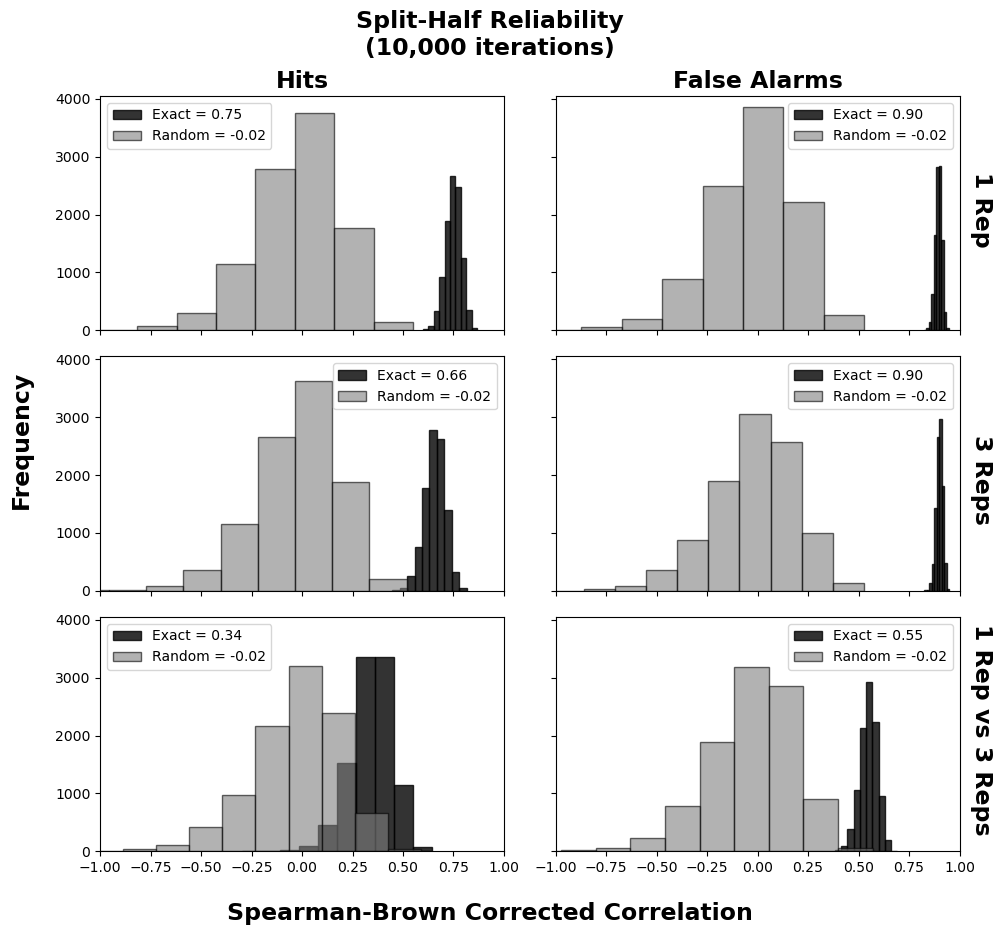

In [82]:
# Combined plot for within and across condition reliability
n_bins = 10

fig, axes = plt.subplots(3, 2, figsize=(10, 10), sharex=True, sharey=True)

cond_map = {
    "1_Rep": "1 Rep",
    "3_Rep": "3 Reps"
}

color_map = {
    "Exact": 'black',
    "Random": 'gray'
}

alpha_map = {
    "Exact": 0.8,
    "Random": 0.6
}

# ----- WITHIN CONDITION (rows 0 and 1) -----
for row, cond in enumerate(["1_Rep", "3_Rep"]):

    # Hits
    axes[row, 0].hist(
        sh_corrs_hits['Exact'][cond],
        color=color_map['Exact'], alpha=alpha_map['Exact'], edgecolor='black',
        bins=n_bins,
        label=f'Exact = {np.mean(sh_corrs_hits["Exact"][cond]):.2f}'
    )

    axes[row, 0].hist(
        sh_corrs_hits['Random'][cond],
        color=color_map['Random'], alpha=alpha_map['Random'], edgecolor='black',
        bins=n_bins,
        label=f'Random = {np.mean(sh_corrs_hits["Random"][cond]):.2f}'
    )

    axes[row, 0].legend()

    # False Alarms
    axes[row, 1].hist(
        sh_corrs_fa['Exact'][cond],
        color=color_map['Exact'], alpha=alpha_map['Exact'], edgecolor='black',
        bins=n_bins,
        label=f'Exact = {np.mean(sh_corrs_fa["Exact"][cond]):.2f}'
    )

    axes[row, 1].hist(
        sh_corrs_fa['Random'][cond],
        color=color_map['Random'], alpha=alpha_map['Random'], edgecolor='black',
        bins=n_bins,
        label=f'Random = {np.mean(sh_corrs_fa["Random"][cond]):.2f}'
    )

    axes[row, 1].legend()


# ----- ACROSS CONDITION (row 2) -----

# Hits
axes[2, 0].hist(
    sh_corrs_hits_across['Exact'],
    color=color_map['Exact'], alpha=alpha_map['Exact'], edgecolor='black',
    bins=n_bins,
    label=f'Exact = {np.mean(sh_corrs_hits_across["Exact"]):.2f}'
)

axes[2, 0].hist(
    sh_corrs_hits_across['Random'],
    color=color_map['Random'], alpha=alpha_map['Random'], edgecolor='black',
    bins=n_bins,
    label=f'Random = {np.mean(sh_corrs_hits_across["Random"]):.2f}'
)

axes[2, 0].legend()


# False Alarms
axes[2, 1].hist(
    sh_corrs_fa_across['Exact'],
    color=color_map['Exact'], alpha=alpha_map['Exact'], edgecolor='black',
    bins=n_bins,
    label=f'Exact = {np.mean(sh_corrs_fa_across["Exact"]):.2f}'
)

axes[2, 1].hist(
    sh_corrs_fa_across['Random'],
    color=color_map['Random'], alpha=alpha_map['Random'], edgecolor='black',
    bins=n_bins,
    label=f'Random = {np.mean(sh_corrs_fa_across["Random"]):.2f}'
)

axes[2, 1].legend()


# ----- Formatting -----
fs_title = 17
fs_ax_labels = 17
fs_grid_labels = 17

for ax in axes.flatten():
    ax.set_xlim(-1, 1)

fig.text(0.5, 0.02, 'Spearman-Brown Corrected Correlation',
         ha='center', fontsize=fs_ax_labels, fontweight='bold')

fig.text(0.02, 0.5, 'Frequency',
         va='center', rotation='vertical', fontsize=fs_ax_labels, fontweight='bold')

plt.suptitle(
    "Split-Half Reliability\n(10,000 iterations)",
    ha='center', y=0.93, fontsize=fs_title, fontweight='bold'
)

# Grid labels
cols = [f'{col}' for col in ['Hits', 'False Alarms']]
rows = [f'{row}' for row in ['1 Rep', '3 Reps', '1 Rep vs 3 Reps']]
row_positions = [0.73, 0.46, 0.21]  # vertical centers of the rows

for ax, col in zip(axes[0], cols):
    ax.set_title(col, fontsize=fs_grid_labels, fontweight='bold')


for y, row in zip(row_positions, rows):
    fig.text(0.98, y, row, va='center', ha='left',
             fontsize=fs_grid_labels, fontweight='bold', rotation=270)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.95])
plt.show()

# H vs FA by distinct

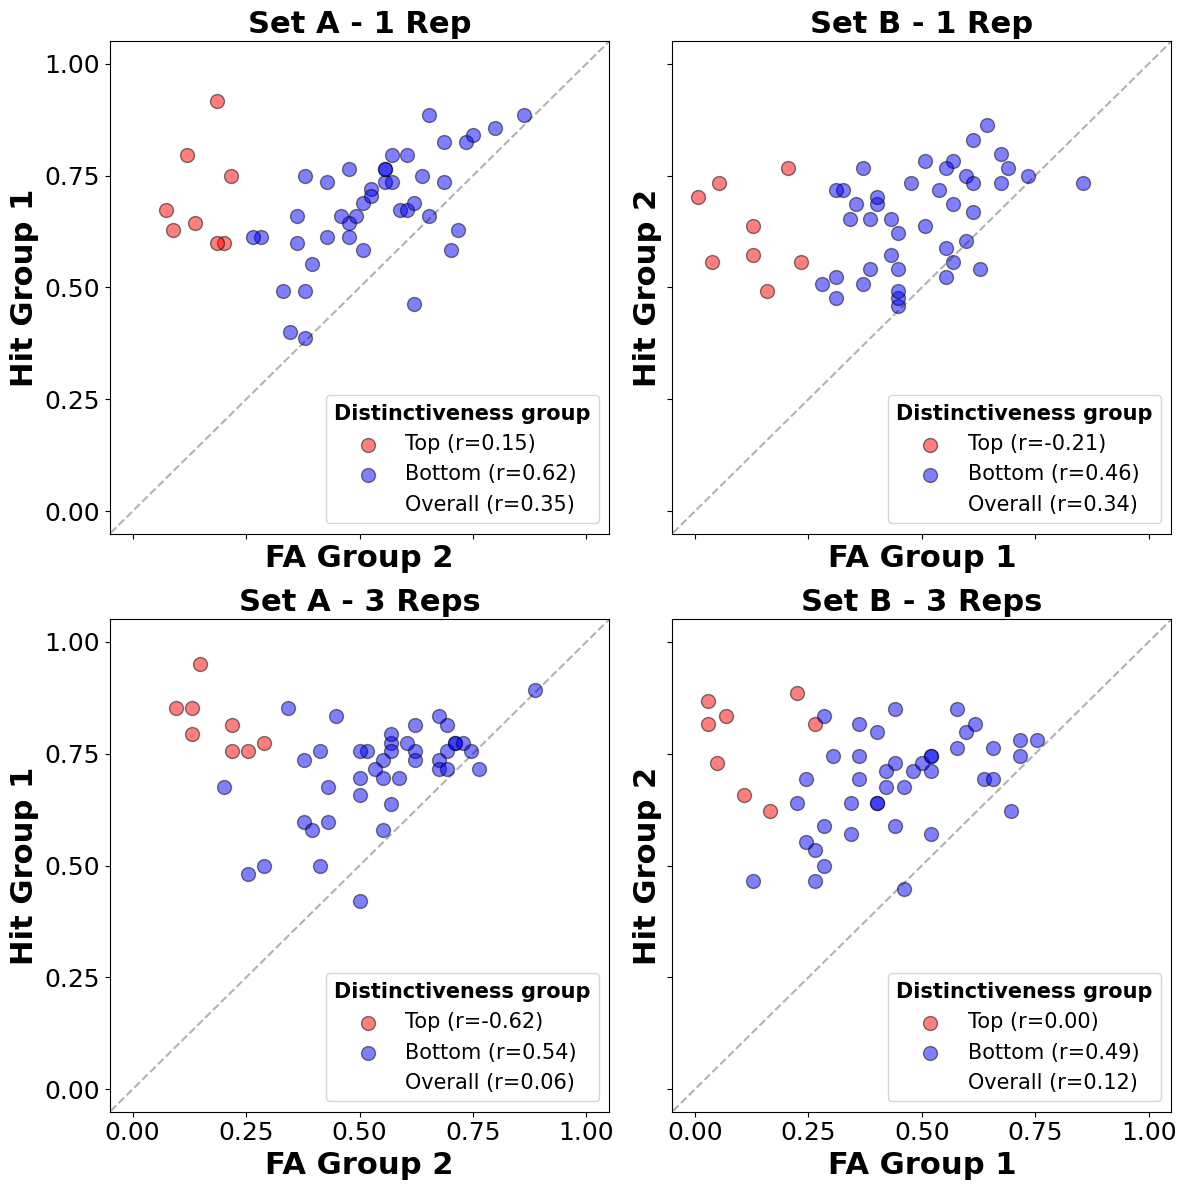

In [93]:
conditions = {'1_Rep': '1 Rep', '3_Rep': '3 Reps'}
sets = {'A': ('FA Group 2', 'Hit Group 1'),
        'B': ('FA Group 1', 'Hit Group 2')}
colors = {'Top': 'red', 'Bottom': 'blue'}
fs, fs_axes, fs_legend = 22, 18, 15
ticks = np.arange(0, 1.1, 0.25)

fig, axes = plt.subplots(2, 2, figsize=(12, 12), sharex=True, sharey=True)

for i, (cond, cond_label) in enumerate(conditions.items()):
    for j, (s, (xlab, ylab)) in enumerate(sets.items()):
        ax = axes[i, j]
        sub = df_by_item_wide[(df_by_item_wide['condition'] == cond) &
                              (df_by_item_wide['set'] == s)]

        for distinct, color in colors.items():
            d = sub[sub['distinct_type'] == distinct]
            r = d['FA'].corr(d['Hit'])
            ax.scatter(d['FA'], d['Hit'], alpha=0.5, edgecolor='k', color=color, s=100,
                       label=f'{distinct} (r={r:.2f})')

        # Overall r as a legend entry without a marker
        ax.plot([], [], ls='None', label=f"Overall (r={sub['FA'].corr(sub['Hit']):.2f})")

        ax.plot([-0.1, 1.1], [-0.1, 1.1], 'k--', alpha=0.3)
        ax.set(xlim=(-0.05, 1.05), ylim=(-0.05, 1.05), xticks=ticks, yticks=ticks)
        ax.set_xlabel(xlab, fontweight='bold', fontsize=fs)
        ax.set_ylabel(ylab, fontweight='bold', fontsize=fs)
        ax.set_title(f'Set {s} - {cond_label}', fontsize=fs, fontweight='bold')
        ax.tick_params(axis='both', labelsize=fs_axes)

        leg = ax.legend(title='Distinctiveness group', fontsize=fs_legend,
                        title_fontsize=fs_legend, loc='lower right')
        leg.get_title().set_fontweight('bold')

plt.tight_layout()
plt.show()

In [ ]:
# H vs FA correlations
# df - df_by_item
def get_H_vs_FA_correlations(df, pred_col='prop_yes'):
    conditions = {'1_Rep': '1 Rep', '3_Rep': '3 Reps'}
    sets = {'A': 'Set A (Group2 FA vs Group1 Hit)',
            'B': 'Set B (Group1 FA vs Group2 Hit)'}

    def pair(sub):
        """FA (x) and Hit (y) values, paired by position."""
        x = sub.loc[sub['resp_type'] == 'FA',  pred_col].reset_index(drop=True)
        y = sub.loc[sub['resp_type'] == 'Hit', pred_col].reset_index(drop=True)
        assert len(x) == len(y), f"FA n={len(x)} != Hit n={len(y)}"
        return x, y

    def report(label, x, y):
        mask = x.notna() & y.notna()
        r, p = pearsonr(x[mask], y[mask])
        print(f"  {label}: r = {r:.2f}, p = {p:.3f}, n = {mask.sum()}")

    print(f"Column: {pred_col}")
    for cond, cond_label in conditions.items():
        print(f"\n===== CONDITION: {cond_label} =====")
        for s, set_label in sets.items():
            print(f"\n{set_label}")
            sub = df[(df['condition'] == cond) & (df['set'] == s)]

            pairs = {d: pair(sub[sub['distinct_type'] == d]) for d in ['Top', 'Bottom']}
            for d, (x, y) in pairs.items():
                report(d, x, y)

            # Overall: concatenate the per-group pairs so pairing is preserved
            x_all = pd.concat([x for x, _ in pairs.values()], ignore_index=True)
            y_all = pd.concat([y for _, y in pairs.values()], ignore_index=True)
            report('Overall', x_all, y_all)

In [95]:
get_H_vs_FA_correlations(df_by_item, pred_col='prop_yes')

Column: prop_yes

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.15, p = 0.716, n = 8
  Bottom: r = 0.62, p = 0.000, n = 42
  Overall: r = 0.35, p = 0.014, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = -0.21, p = 0.616, n = 8
  Bottom: r = 0.46, p = 0.002, n = 42
  Overall: r = 0.34, p = 0.016, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = -0.62, p = 0.100, n = 8
  Bottom: r = 0.54, p = 0.000, n = 42
  Overall: r = 0.06, p = 0.694, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.00, p = 0.995, n = 8
  Bottom: r = 0.49, p = 0.001, n = 42
  Overall: r = 0.12, p = 0.409, n = 50


# Models

## Hybrid-Similarity Model

Hybrid-Similarity Model. 

$$P( 'Old' | i) = P( 'Old' | F_i) = \frac{F_i}{F_i + k}$$

where $F_i$ is the object $i$'s familiarity and $k$ is a free parameter. 

$F_i = \sum_{j = 1}^{J} S_{ij}$, where $S_{ij}$ is the similarity between test item $i$ to all study items $j$. 

$S_{ij}$ is based on 
1. The distances between items $i$ and $j$ in the similarity space: $S_{ij} = e^{-c \times D_{ij}}$ ($c$ is a free parameter, $D_{ij} = \sqrt{ \sum_{m=1}^M (x_{im} - x_{jm})^2 } $ is the distance in the $M$-dimensional space)
2. And on the distinctivenes ratings: $S_{ii} = e^{\beta \times d_i} \times e^{-c \times D_{ij}} = e^{\beta \times d_i} \times 1 = e^{\beta \times d_i}$, if $i$ is an old item and $S_{ij} = e^{\alpha \times d_i} \times e^{-c \times D_{ij}}$, if $i$ is a new item, where $\alpha$ and $\beta$ are free parameters, and $d_i$ is the distinctiveness rating of item $i$.

In [96]:
# Load MDS solution
mds_solution = pd.read_csv('https://raw.githubusercontent.com/DaniilAzarov123/Rocks_Database/main/info/Rocks480_MDS8_solution.csv')
mds_solution

,image_id,dim1,dim2,dim3,dim4,dim5,dim6,dim7,dim8
0,1,-2.757,-1.594,1.052,0.768,1.343,1.711,1.795,0.809
1,2,2.001,-0.754,1.405,-1.382,-1.384,0.976,-0.067,1.972
2,3,0.261,-0.508,-2.962,-0.608,0.009,-0.191,2.720,-1.224
3,4,0.382,-0.027,-0.148,-1.899,-1.948,1.862,0.968,0.986
4,5,0.288,2.013,-1.102,-1.285,0.344,-0.009,2.696,-0.174
...,...,...,...,...,...,...,...,...,...
475,476,0.749,-3.021,-1.908,-1.689,-0.493,4.441,-0.122,1.618
476,477,-0.054,-2.743,-1.435,-2.903,0.315,3.161,1.833,1.288
477,478,0.007,-2.077,-4.012,-1.633,-0.366,2.558,4.210,-0.060
478,479,0.177,-2.520,-2.293,-1.216,0.545,0.805,2.302,0.629


In [97]:
# study lists
study_list_gr1 = np.sort(filtered_data_memory.loc[filtered_data_memory['group']=='Group1', 'image_id'].unique())
study_list_gr2 = np.sort(filtered_data_memory.loc[filtered_data_memory['group']=='Group2', 'image_id'].unique())

# test list
test_list = np.sort(filtered_data_test['image_id'].unique())

In [98]:
# Calculate distances

# Step 1: Extract the MDS coordinates (first 8 columns)
# Make sure image_id is set as the index for easy lookup
mds_coords = mds_solution.set_index('image_id').iloc[:, :8]

# ------------- Group 1 ----------

# Step 2: Get row and column names from dist_mat_gr1
row_ids = test_list 
col_ids = study_list_gr1

# Step 3: Extract MDS coordinates for rows and columns
# This creates matrices where each row/column corresponds to the image_ids
mds_rows = mds_coords.loc[row_ids].values  # Shape: (240, 8)
mds_cols = mds_coords.loc[col_ids].values  # Shape: (120, 8)

# Step 4: Calculate Euclidean distances efficiently
# Using broadcasting: expand dimensions to compute all pairwise distances at once
# mds_rows[:, np.newaxis, :] has shape (240, 1, 8)
# mds_cols[np.newaxis, :, :] has shape (1, 120, 8)
# The difference has shape (240, 120, 8)
diff = mds_rows[:, np.newaxis, :] - mds_cols[np.newaxis, :, :]

# Calculate Euclidean distance: sqrt of sum of squared differences
distances = np.sqrt(np.sum(diff**2, axis=2))

# Step 5: Create a DataFrame with the same structure as dist_mat_gr1
dist_mat_gr1 = pd.DataFrame(
    distances,
    index=row_ids,
    columns=col_ids
)

# ------------- Group 2 ----------

# Step 2: Get row and column names from dist_mat_gr1
row_ids = test_list 
col_ids = study_list_gr2

# Step 3: Extract MDS coordinates for rows and columns
# This creates matrices where each row/column corresponds to the image_ids
mds_rows = mds_coords.loc[row_ids].values  # Shape: (240, 8)
mds_cols = mds_coords.loc[col_ids].values  # Shape: (120, 8)

# Step 4: Calculate Euclidean distances efficiently
# Using broadcasting: expand dimensions to compute all pairwise distances at once
# mds_rows[:, np.newaxis, :] has shape (240, 1, 8)
# mds_cols[np.newaxis, :, :] has shape (1, 120, 8)
# The difference has shape (240, 120, 8)
diff = mds_rows[:, np.newaxis, :] - mds_cols[np.newaxis, :, :]

# Calculate Euclidean distance: sqrt of sum of squared differences
distances = np.sqrt(np.sum(diff**2, axis=2))

# Step 5: Create a DataFrame with the same structure as dist_mat_gr1
dist_mat_gr2 = pd.DataFrame(
    distances,
    index=row_ids,
    columns=col_ids
)

In `dist_mat_gr1` (100x50) and `dist_mat_gr2` (100x50), each row is each test item (they are the **same** accross two matrices), and each column is each study item (they are **different** accross matrices).

In [99]:
# Dicionary comprehension: {image_id: distinctiveness}
distinctiveness_image_id = df_by_item.set_index('image_id')['distinct_rating'].to_dict()
list(distinctiveness_image_id.items())[:5] # first 5 items

[(3, 3.17), (4, 3.18), (6, 3.17), (8, 1.95), (9, 2.49)]

In [100]:
# Transform similarities based on distinctiveness ratings:
# increased self-similarity for more distinctive items and decreased similarity to other items for more distinctive items
def transform_similarity_matrix(alpha, beta, 
                                similarity_matrix, 
                                distinctiveness_dict = distinctiveness_image_id):
    # Create a copy to avoid modifying the original
    transformed = similarity_matrix.copy()
    
    # Iterate through each row
    for row_id in transformed.index:
        # Get distinctiveness for this row's image
        distinct_i = distinctiveness_dict[row_id]
        
        # Iterate through each column
        for col_id in transformed.columns:
            s_ij = similarity_matrix.loc[row_id, col_id]
            
            if row_id == col_id:
                # Self-similarity case: exp(beta * distinct_i)
                # Since s_ii = 1
                transformed.loc[row_id, col_id] = np.exp(beta * distinct_i)
            else:
                # Similarity between different items (item i and item j) case
                # s_ij * exp(-alpha * distinct_i)
                transformed.loc[row_id, col_id] = np.exp(-alpha * distinct_i) * s_ij
    
    return transformed

In [101]:
# For NegLogLikelihood calculation
filtered_data_test['responded_old'] = np.where(filtered_data_test['response'] == "l", 1, 0)
filtered_data_test

,trial_index,subject_id,group,condition,task,item_type,response,correct_response,cor_ans,rt,...,category,broad_category,image_png,image_id,distinct_rating,distinct_type,set,good_subj,resp_type,responded_old
0,311,91746,Group2,3_Rep,test_phase,Target,l,l,True,1776.0,...,13,M,M_Gneiss_15.png,207,3.11,Bottom,B,True,Hit,1
1,313,91746,Group2,3_Rep,test_phase,Target,l,l,True,767.0,...,28,S,S_Rock Salt_13.png,445,7.58,Top,B,True,Hit,1
2,315,91746,Group2,3_Rep,test_phase,Target,l,l,True,779.0,...,7,I,I_Pegmatite_03.png,99,7.24,Top,B,True,Hit,1
3,317,91746,Group2,3_Rep,test_phase,Target,l,l,True,805.0,...,13,M,M_Gneiss_10.png,202,3.09,Bottom,B,True,Hit,1
4,319,91746,Group2,3_Rep,test_phase,Foil,a,a,True,924.0,...,10,I,I_Rhyolite_16.png,160,2.19,Bottom,A,True,CR,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23195,501,92625,Group2,3_Rep,test_phase,Foil,a,a,True,1088.0,...,6,I,I_Obsidian_05.png,85,7.32,Top,A,True,CR,0
23196,503,92625,Group2,3_Rep,test_phase,Target,l,l,True,815.0,...,13,M,M_Gneiss_10.png,202,3.09,Bottom,B,True,Hit,1
23197,505,92625,Group2,3_Rep,test_phase,Foil,l,a,False,1000.0,...,15,M,M_Marble_04.png,228,3.15,Bottom,A,True,FA,1
23198,507,92625,Group2,3_Rep,test_phase,Target,l,l,True,683.0,...,13,M,M_Gneiss_14.png,206,3.41,Bottom,B,True,Hit,1


In [102]:
# Different parameters for different groups

def HS_model(parameters,
             data, 
             distances_mats_list = [dist_mat_gr1, dist_mat_gr2], 
             distinctiveness_dict = distinctiveness_image_id):
    # parameters
    c, alpha, beta, k = parameters
    
    # get group name
    group = data['group'].unique()[0]
    groupN = 0 if group == 'Group1' else 1
    
    # Distances matrices
    distances_mat = distances_mats_list[groupN]
    
    # (Raw) Similarity matrices
    similarity_mat = np.exp(-c * distances_mat)
    
    # Transform similarities based on distinctiveness ratings
    similarity_mat_transformed = transform_similarity_matrix(alpha=alpha, beta=beta, 
                                                             similarity_matrix=similarity_mat, distinctiveness_dict=distinctiveness_dict)
    
    # Summed similarities (familiarity) for each item
    familiarity = np.sum(similarity_mat_transformed, axis=1)
    
    # Expand familiarities for each subject (to match the test data)
    familiarities = []
    for _, row in data.iterrows():
        image_id = row['image_id']
        familiarity_i_subj = familiarity.loc[familiarity.index == image_id]        
        familiarities.append(familiarity_i_subj.values[0] if not familiarity_i_subj.empty else np.nan)
    
    # Predicted proportions of "Old" responses ("Yes")
    predictions = [fam / (fam + k) for fam in familiarities]
    
    return predictions    

# Optimization

We fit the same parameters to both groups, e.g. group 1 and group 2 share the same sensitivity parameter $c$.

In [103]:
# NLL function for pooled data across groups
def NegLogLikelihood_pooled(parameters,
                             model_function,
                             df_observed, # data for BOTH groups, one condition
                             distances_mats_list=[dist_mat_gr1, dist_mat_gr2],
                             distinctiveness_dict=distinctiveness_image_id):
    total_nll = 0
    epsilon = 1e-10

    # Loop over groups, apply the SAME parameters, sum the NLL
    for group in ['Group1', 'Group2']:
        df_group = df_observed.loc[df_observed['group'] == group]
        if df_group.empty:
            print(f"Warning: No data for {group} in the provided df_observed")

        predicted = model_function(parameters, df_group, distances_mats_list, distinctiveness_dict)

        df_merged = df_group.copy()
        df_merged['prop_yes_pred'] = predicted
        df_merged['prop_yes_pred'] = df_merged['prop_yes_pred'].clip(epsilon, 1 - epsilon)

        log_likelihood = (
            df_merged['responded_old'] * np.log(df_merged['prop_yes_pred']) +
            (1 - df_merged['responded_old']) * np.log(1 - df_merged['prop_yes_pred'])
        )
        total_nll += -log_likelihood.sum()

    return total_nll

In [105]:
# Store optimization results in a dictionary
# for each model, condition and group
optimization_result = {}

## HS (pooled across groups)

In [106]:
# ---- Optimize: 4 params * 2 conditions = 8 total ----
initial_params = [1, 1, 1, 1]  # c, alpha, beta, k
model = 'HS_pooled_groups_model'
optimization_result[model] = {}
conditions = ['1_Rep', '3_Rep']

for condition in conditions:
    print(f"Optimizing for {condition} (pooled across groups)...")

    df_observed = filtered_data_test.loc[filtered_data_test["condition"] == condition]

    result = minimize(
        NegLogLikelihood_pooled, # use this NLL function for pooled data
        initial_params,
        args=(HS_model, df_observed, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id),
        method='Nelder-Mead',
        options={'maxiter': 1000, 'disp': True}
    )

    optimization_result[model][condition] = result

    print(f"Best parameters for {condition}: {result.x}")
    print(f"Negative Log-Likelihood: {result.fun}\n")

    if not result.success:
        print("=============== Attention: Optimization did not converge! ===============\n")


Optimizing for 1_Rep (pooled across groups)...
Optimization terminated successfully.
         Current function value: 8053.674438
         Iterations: 201
         Function evaluations: 334
Best parameters for 1_Rep: [0.61545937 0.12762878 0.16502192 1.66222557]
Negative Log-Likelihood: 8053.674437977645

Optimizing for 3_Rep (pooled across groups)...
Optimization terminated successfully.
         Current function value: 6562.666037
         Iterations: 199
         Function evaluations: 338
Best parameters for 3_Rep: [0.66660632 0.09392642 0.25329765 1.52664512]
Negative Log-Likelihood: 6562.666037184865



In [110]:
# Best parameters
print("Best parameters (pooled model):\n")
param_names = ['c', 'alpha', 'beta', 'k']
for condition, res in optimization_result[model].items():
    params = res.x
    print(f"{condition}:\n {', '.join([p + ': ' + str(round(p_val, 3)) for p, p_val in zip(param_names, params)])}\n")


Best parameters (pooled model):

1_Rep:
 c: 0.615, alpha: 0.128, beta: 0.165, k: 1.662

3_Rep:
 c: 0.667, alpha: 0.094, beta: 0.253, k: 1.527



In [111]:
# Predict using pooled parameters
filtered_data_test['HS_pooled_groups_preds'] = np.nan

for condition in conditions:
    optimal_params = optimization_result[model][condition].x

    for group in ['Group1', 'Group2']:
        mask = (filtered_data_test["group"] == group) & (filtered_data_test["condition"] == condition)
        data_subset = filtered_data_test.loc[mask]

        predictions = HS_model(optimal_params, data_subset, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id)
        filtered_data_test.loc[mask, 'HS_pooled_groups_preds'] = predictions

In [118]:
# Merge mean predictions into df_by_item, as with the other models
df_by_item = pd.merge(df_by_item,
                      pd.pivot_table(filtered_data_test,
                                     index=['image_id','group', 'condition'],
                                     values='HS_pooled_groups_preds',
                                     aggfunc='mean',
                                     observed=True).reset_index(),
                      on=['image_id', 'group', 'condition']
                      )

## Base model optim

$\alpha = 0$ and $\beta = 0$ are fixed, $c$ and $k$ are free to vary but they are shared across groups

In [120]:
# ---- Optimize: 2 free params (c, k) * 2 conditions = 4 total; alpha=0, beta=0 fixed ----
initial_params_reduced = [1, 1]  # c, k
model = 'Base_model'
optimization_result[model] = {}
conditions = ['1_Rep', '3_Rep']

for condition in conditions:
    print(f"Optimizing for {condition}...")

    df_observed = filtered_data_test.loc[filtered_data_test["condition"] == condition]

    result = minimize(
        lambda params, *args: NegLogLikelihood_pooled([params[0], 0, 0, params[1]], *args),
        initial_params_reduced,
        args=(HS_model, df_observed, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id),
        method='Nelder-Mead',
        options={'maxiter': 1000, 'disp': True}
    )

    optimization_result[model][condition] = result

    print(f"Best parameters for {condition} (c, k): {result.x}")
    print(f"Negative Log-Likelihood: {result.fun}\n")

    if not result.success:
        print("=============== Attention: Optimization did not converge! ===============\n")

Optimizing for 1_Rep...
Optimization terminated successfully.
         Current function value: 8097.469507
         Iterations: 32
         Function evaluations: 63
Best parameters for 1_Rep (c, k): [0.87637827 0.8381924 ]
Negative Log-Likelihood: 8097.4695069013615

Optimizing for 3_Rep...
Optimization terminated successfully.
         Current function value: 6648.403667
         Iterations: 37
         Function evaluations: 71
Best parameters for 3_Rep (c, k): [0.96922097 0.60438703]
Negative Log-Likelihood: 6648.403667264813



In [124]:
# Best parameters
print("Best parameters:\n")
param_names = ['c', 'k']
for condition, res in optimization_result[model].items():
    params = res.x
    print(f"{condition}:\n {', '.join([p + ': ' + str(round(p_val, 3)) for p, p_val in zip(param_names, params)])}\n")


Best parameters:

1_Rep:
 c: 0.876, k: 0.838

3_Rep:
 c: 0.969, k: 0.604



In [125]:
# Predict using pooled parameters
filtered_data_test['Base_preds'] = np.nan

for condition in conditions:
    optimal_params_reduced = optimization_result[model][condition].x
    optimal_params = [optimal_params_reduced[0], 0, 0, optimal_params_reduced[1]]

    for group in ['Group1', 'Group2']:
        mask = (filtered_data_test["group"] == group) & (filtered_data_test["condition"] == condition)
        data_subset = filtered_data_test.loc[mask]

        predictions = HS_model(optimal_params, data_subset, [dist_mat_gr1, dist_mat_gr2], distinctiveness_image_id)
        filtered_data_test.loc[mask, 'Base_preds'] = predictions

In [126]:
# Add predictions to df_by_item (mean per item)
df_by_item = pd.merge(df_by_item, 
                      pd.pivot_table(filtered_data_test, 
                                     index=['image_id','group', 'condition'], 
                                     values='Base_preds', 
                                     aggfunc='mean',
                                     observed=True).reset_index(),
                      on=['image_id', 'group', 'condition']
                      )
df_by_item

,image_id,condition,group,item_type,set,distinct_type,distinct_rating,category_name,n_subj,n_yes,prop_yes,resp_type,HS_pooled_groups_preds,Base_preds
0,3,1_Rep,Group1,Foil,B,Bottom,3.17,Andesite,65,20,0.310606,FA,0.516068,0.531276
1,3,1_Rep,Group2,Target,B,Bottom,3.17,Andesite,61,32,0.524194,Hit,0.641501,0.662828
2,3,3_Rep,Group1,Foil,B,Bottom,3.17,Andesite,50,14,0.284314,FA,0.511542,0.527527
3,3,3_Rep,Group2,Target,B,Bottom,3.17,Andesite,56,28,0.500000,Hit,0.688549,0.706409
4,4,1_Rep,Group1,Foil,B,Bottom,3.18,Andesite,65,37,0.568182,FA,0.488979,0.461235
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,472,3_Rep,Group2,Foil,A,Bottom,2.55,Shale,56,14,0.254386,FA,0.467164,0.450899
396,476,1_Rep,Group1,Target,A,Bottom,2.48,Shale,65,46,0.704545,Hit,0.661792,0.683822
397,476,1_Rep,Group2,Foil,A,Bottom,2.48,Shale,61,32,0.524194,FA,0.541082,0.537338
398,476,3_Rep,Group1,Target,A,Bottom,2.48,Shale,50,40,0.794118,Hit,0.690038,0.721421


## All parameters

In [194]:
param_names = ["c", "alpha", "beta", "k"]
models = list(optimization_result)

all_params = []
for model in models:
    for key, res in optimization_result[model].items():
        # Pooled fits are keyed by condition; per-group fits by (group, condition)
        group, condition = key if isinstance(key, tuple) else ("Pooled", key)

        if len(res.x) == 4:              # c, alpha, beta, k
            params, fixed = res.x, ""
        elif len(res.x) == 2:            # c, k  (alpha = beta = 0 fixed)
            params, fixed = [res.x[0], 0.0, 0.0, res.x[1]], "alpha, beta = 0"
        else:
            raise ValueError(f"{model} {key}: unexpected number of params ({len(res.x)})")

        all_params.append({"model": model, "group": group, "condition": condition,
                           **dict(zip(param_names, params)),
                           "fixed": fixed, "nll": res.fun, "converged": res.success})
        
all_params = (pd.DataFrame(all_params)
              .sort_values(["model", "group", "condition"])
              .reset_index(drop=True))
all_params

,model,group,condition,c,alpha,beta,k,fixed,nll,converged
0,Base_model,Pooled,1_Rep,0.876378,0.000000,0.000000,0.838192,"alpha, beta = 0",8097.469507,True
1,Base_model,Pooled,3_Rep,0.969221,0.000000,0.000000,0.604387,"alpha, beta = 0",6648.403667,True
2,HS_pooled_groups_model,Pooled,1_Rep,0.615459,0.127629,0.165022,1.662226,,8053.674438,True
3,HS_pooled_groups_model,Pooled,3_Rep,0.666606,0.093926,0.253298,1.526645,,6562.666037,True


# Visualization

## Pred vs Real

In [127]:
# Function to plot model fit by distinctiveness
def plot_model_fit_by_distinctiveness(df_by_item, pred_col, model_label,
                                       fs=22, fs_axes=18, fs_legend=14):
    conditions = ['1_Rep', '3_Rep']
    condition_labels = ['1 Repetition', '3 Repetitions']
    resp_types = ['Hit', 'FA']

    color_map = {'Top': ('red', 0.5), 'Bottom': ('blue', 0.5)}

    fig, axes = plt.subplots(2, 2, figsize=(14, 14), sharex=True, sharey=True)

    for row_idx, (condition, condition_label) in enumerate(zip(conditions, condition_labels)):
        df_cond = df_by_item[df_by_item['condition'] == condition]

        for col_idx, resp_type in enumerate(resp_types):
            ax = axes[row_idx, col_idx]
            df_rt = df_cond[df_cond['resp_type'] == resp_type]

            # Overall correlation for this condition x response type (both distinct groups combined)
            r_overall, _ = stats.pearsonr(df_rt['prop_yes'], df_rt[pred_col])

            for distinct_type, (color, alpha) in color_map.items():
                df_sub = df_rt[df_rt['distinct_type'] == distinct_type]
                if df_sub.empty:
                    continue
                x = df_sub[pred_col]
                y = df_sub['prop_yes']

                if len(df_sub) > 1:
                    r, _ = stats.pearsonr(x, y)
                    label = f'{distinct_type} (r={r:.2f})'
                else:
                    label = distinct_type

                ax.scatter(x, y, alpha=alpha, s=70, color=color, label=label)

            overall_handle = Line2D([], [], linestyle='None', label=f'Overall (r={r_overall:.2f})')
            handles, labels = ax.get_legend_handles_labels()
            leg = ax.legend(handles + [overall_handle], labels + [overall_handle.get_label()],
                         fontsize=fs_legend, loc='upper left', title='Distinctiveness')
            leg.get_title().set_fontweight('bold')
            leg.get_title().set_fontsize(fs_legend)

            ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
            ax.set_xlim(-0.05, 1.05)
            ax.set_ylim(-0.05, 1.05)
            ax.set_xticks(np.arange(0, 1.05, 0.25))
            ax.set_yticks(np.arange(0, 1.05, 0.25))
            ax.tick_params(axis='both', labelsize=fs_axes)

            if row_idx == 0:
                ax.set_title(resp_type, fontsize=fs, fontweight='bold')
            if col_idx == 0:
                ax.set_ylabel(condition_label, fontsize=fs, fontweight='bold')

    fig.suptitle(model_label, fontsize=fs + 2, fontweight='bold', y=1.02)
    fig.text(0.5, -0.02, 'Predicted Proportion "Old"', fontsize=fs, fontweight='bold', ha='center')
    fig.text(-0.03, 0.5, 'Observed Proportion "Old"', fontsize=fs, fontweight='bold', va='center', rotation=90)
    plt.tight_layout()
    plt.show()

In [128]:
# Compute the exact correlations
# (Same as shown on the scatter plots, but now in a table format)
def compute_model_correlations_by_distinctiveness(df_by_item, pred_col, model_label=None):
    conds = ['1_Rep', '3_Rep']
    resp_types = ['Hit', 'FA']

    def r_p(x, y):
        r, p = stats.pearsonr(x, y)
        return round(r, 3), ("< .001" if p < 0.001 else f"{p:.3f}")

    for cond in conds:
        df_cond = df_by_item[df_by_item['condition'] == cond]
        rows = []

        for resp_type in resp_types:
            df_rt = df_cond[df_cond['resp_type'] == resp_type]

            # by distinctiveness (Top / Bottom), matching the scatter colors
            for distinct_type in ['Top', 'Bottom']:
                df_sub = df_rt[df_rt['distinct_type'] == distinct_type]
                if len(df_sub) > 1:
                    r, p = r_p(df_sub['prop_yes'], df_sub[pred_col])
                else:
                    r, p = (np.nan, 'n/a')
                rows.append({'resp_type': resp_type, 'distinct_type': distinct_type, 'r': r, 'p_value': p})

            # overall for this resp_type (Top + Bottom combined)
            r, p = r_p(df_rt['prop_yes'], df_rt[pred_col])
            rows.append({'resp_type': resp_type, 'distinct_type': 'Overall', 'r': r, 'p_value': p})

        # grand overall (across resp_types and distinct_types)
        r, p = r_p(df_cond['prop_yes'], df_cond[pred_col])
        rows.append({'resp_type': 'Overall', 'distinct_type': 'Overall', 'r': r, 'p_value': p})

        df_model_correlations = pd.DataFrame(rows)

        header = f'{model_label} - {cond}' if model_label else cond
        print(f'{"="*10} {header} {"="*10}')
        print(df_model_correlations, end="\n\n")

    return None

### HS pooled

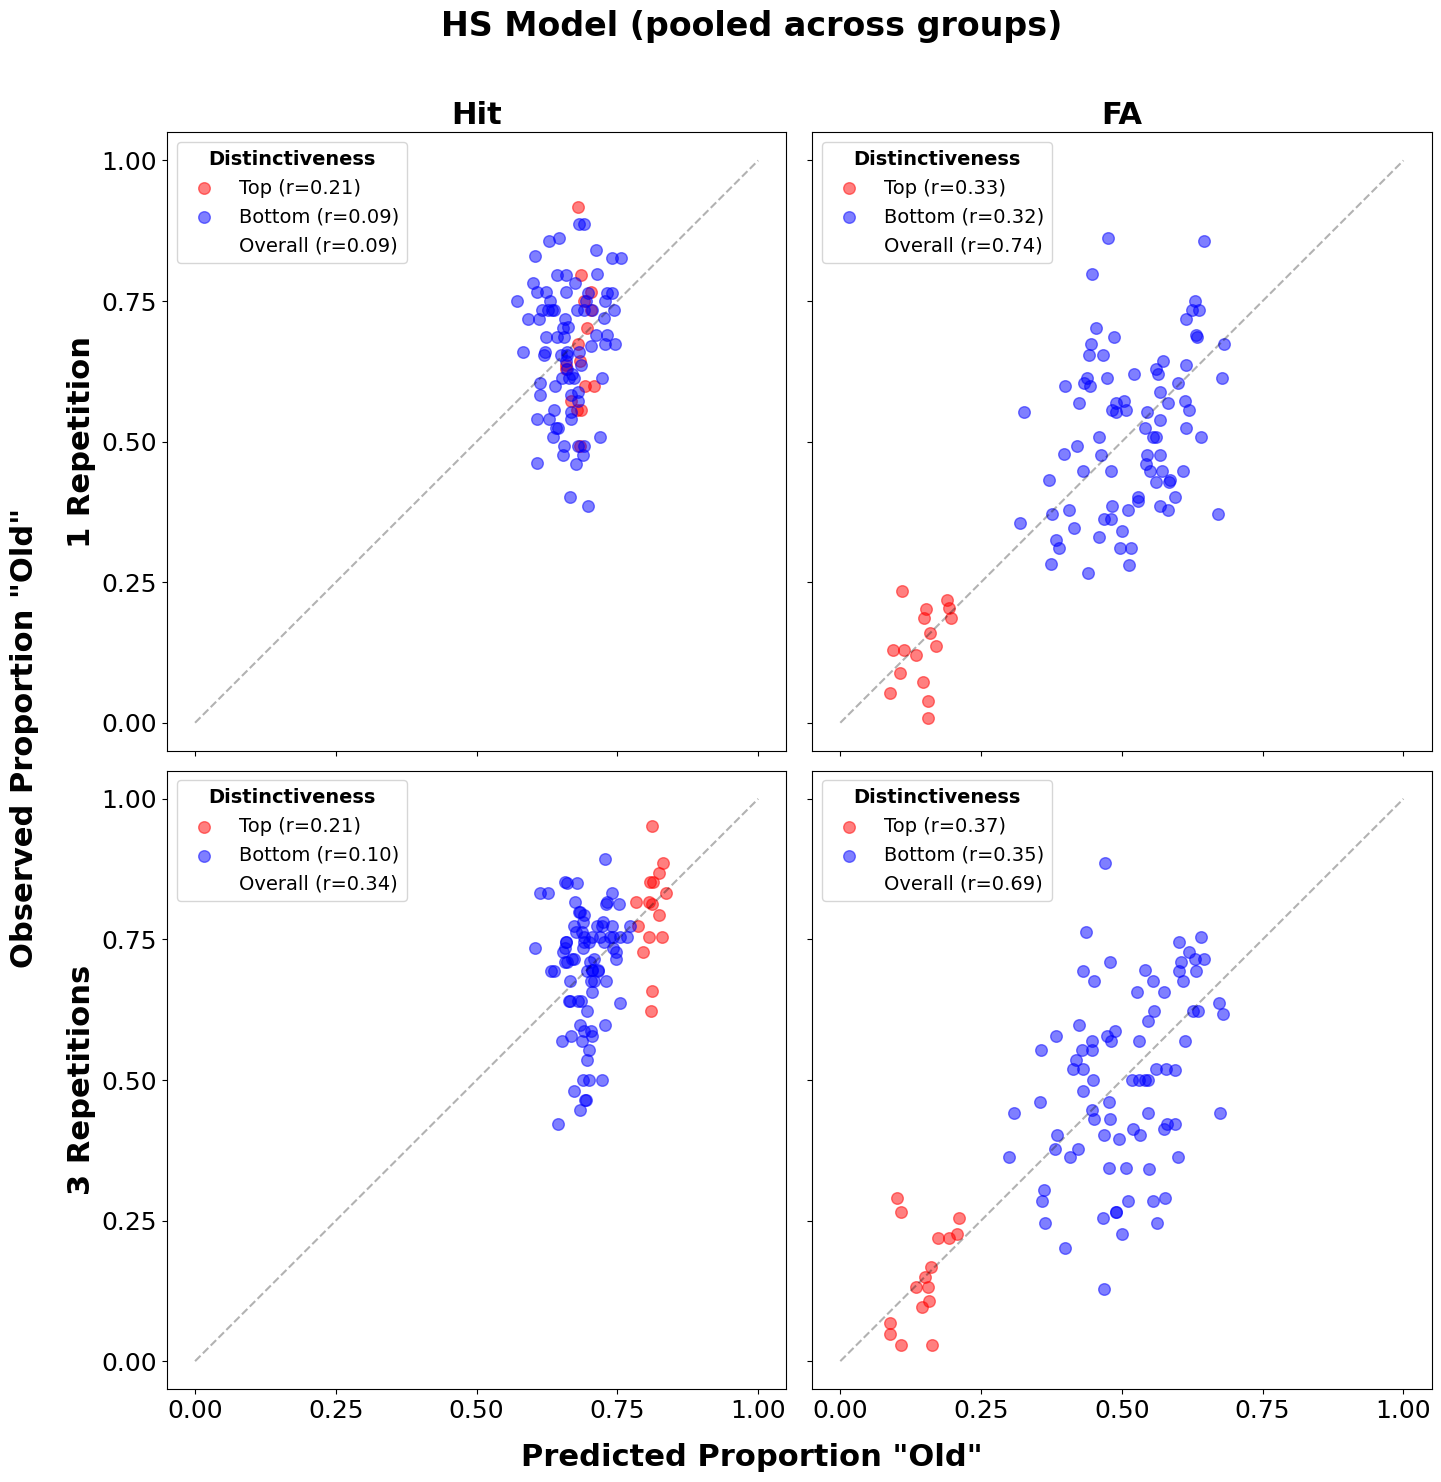

In [129]:
# Plot
plot_model_fit_by_distinctiveness(df_by_item, 'HS_pooled_groups_preds', 'HS Model (pooled across groups)')

In [130]:
# Correlations
compute_model_correlations_by_distinctiveness(df_by_item, 'HS_pooled_groups_preds', 'HS Model (pooled across groups)')

========== HS Model (pooled across groups) - 1_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.205   0.445
1       Hit        Bottom  0.092   0.407
2       Hit       Overall  0.092   0.364
3        FA           Top  0.330   0.212
4        FA        Bottom  0.322   0.003
5        FA       Overall  0.745  < .001
6   Overall       Overall  0.763  < .001

========== HS Model (pooled across groups) - 3_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.213   0.428
1       Hit        Bottom  0.103   0.353
2       Hit       Overall  0.336  < .001
3        FA           Top  0.369   0.160
4        FA        Bottom  0.355  < .001
5        FA       Overall  0.694  < .001
6   Overall       Overall  0.802  < .001



### Base model

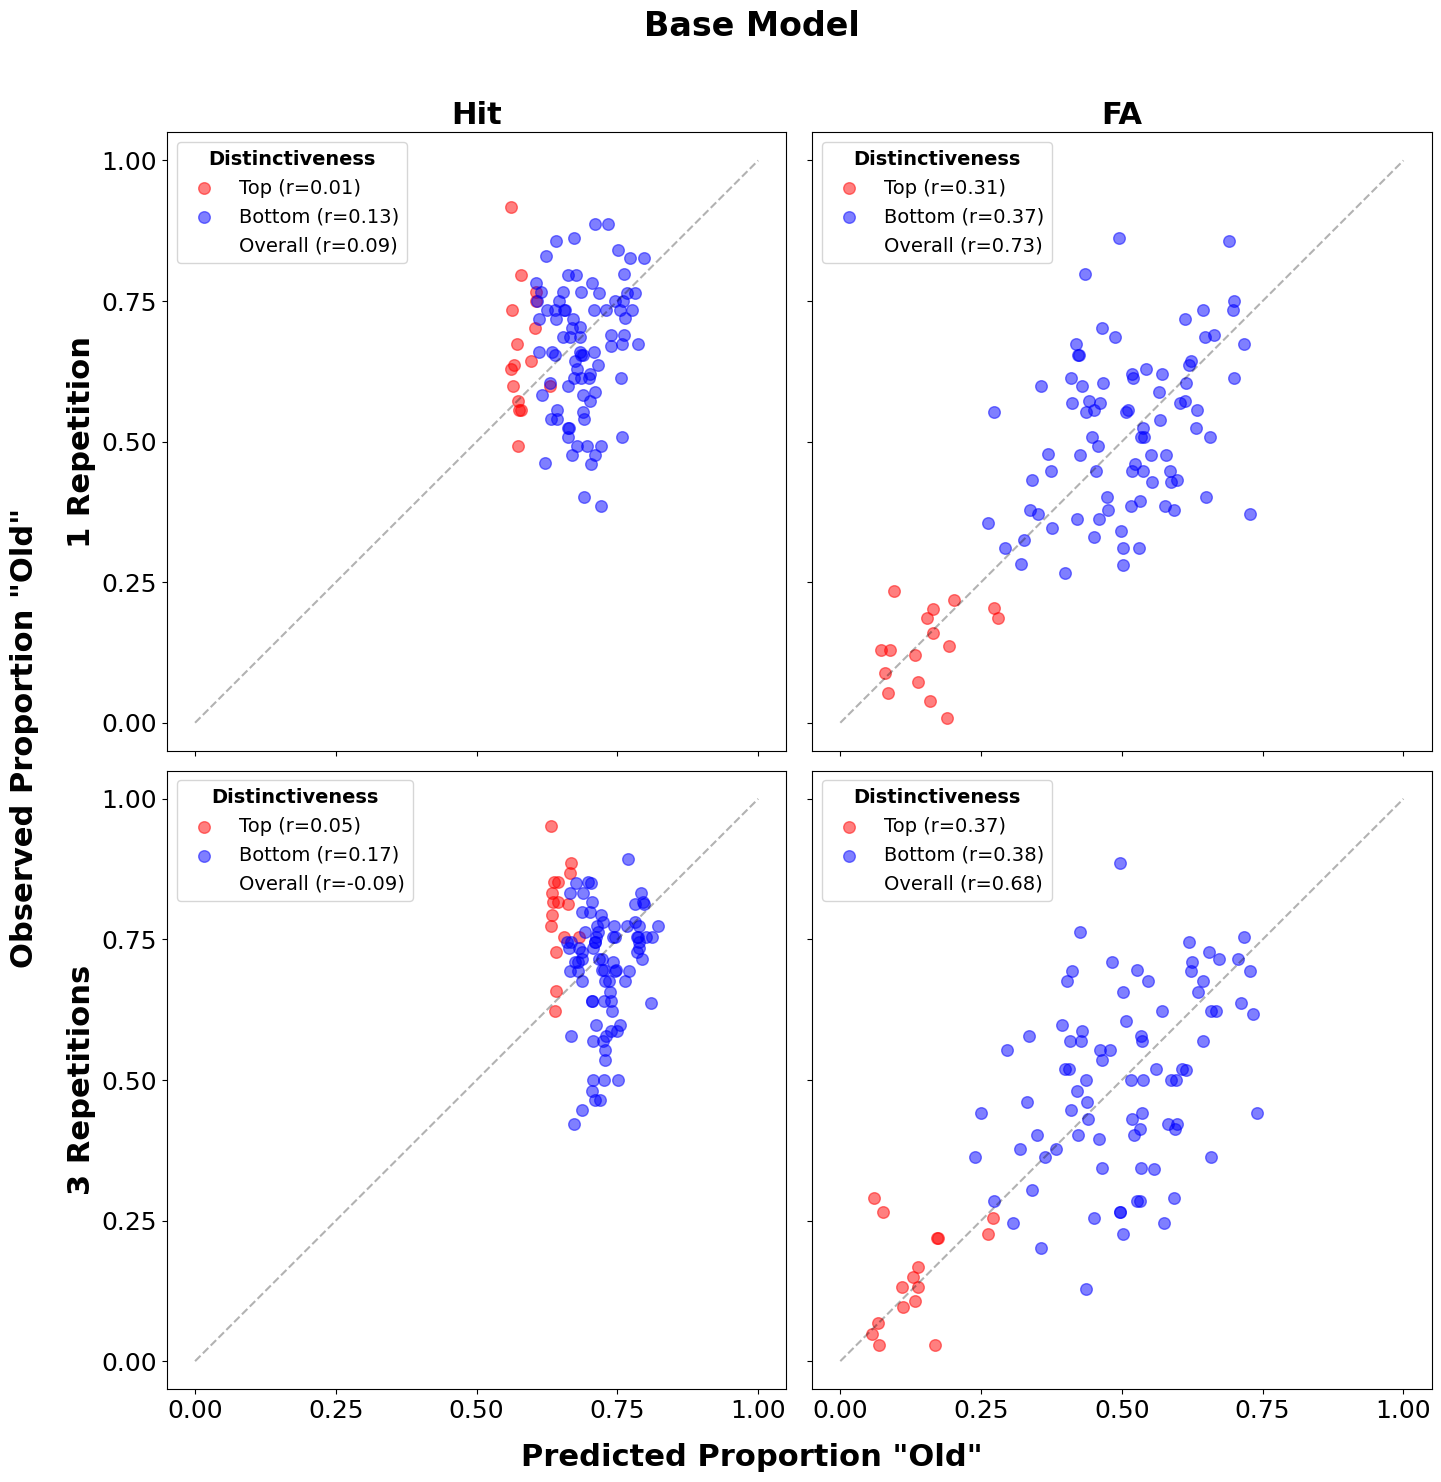

In [131]:
# Plot
plot_model_fit_by_distinctiveness(df_by_item, 'Base_preds', 'Base Model')

In [132]:
# Correlations
compute_model_correlations_by_distinctiveness(df_by_item, 'Base_preds', 'Base Model')

========== Base Model - 1_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.012   0.966
1       Hit        Bottom  0.128   0.247
2       Hit       Overall  0.095   0.348
3        FA           Top  0.308   0.246
4        FA        Bottom  0.371  < .001
5        FA       Overall  0.731  < .001
6   Overall       Overall  0.746  < .001

========== Base Model - 3_Rep ==========
  resp_type distinct_type      r p_value
0       Hit           Top  0.052   0.849
1       Hit        Bottom  0.171   0.119
2       Hit       Overall -0.094   0.353
3        FA           Top  0.366   0.163
4        FA        Bottom  0.375  < .001
5        FA       Overall  0.683  < .001
6   Overall       Overall  0.765  < .001



## H vs FA

In [139]:
def plot_hit_fa_cross_correlations(df_by_item, pred_col, model_label):
    conditions = ['1_Rep', '3_Rep']   # rows
    sets = {'A': ('FA group 2', 'Hit group 1'),   # columns
            'B': ('FA group 1', 'Hit group 2')}
    distinct_groups = {'Top': ('High', 'red'), 'Bottom': ('Low', 'blue')}
    fs, fs_axes, fs_legend = 22, 18, 15
    ticks = np.arange(0, 1.1, 0.25)

    def pair(sub):
        """FA (x) and Hit (y) values, paired by position."""
        x = sub.loc[sub['resp_type'] == 'FA',  pred_col].reset_index(drop=True)
        y = sub.loc[sub['resp_type'] == 'Hit', pred_col].reset_index(drop=True)
        assert len(x) == len(y), f"FA n={len(x)} != Hit n={len(y)}"
        return x, y

    fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)

    for i, cond in enumerate(conditions):
        for j, (s, (xlab, ylab)) in enumerate(sets.items()):
            ax = axes[i, j]
            sub = df_by_item[(df_by_item['condition'] == cond) & (df_by_item['set'] == s)]

            xs, ys = [], []
            for distinct, (dist_name, color) in distinct_groups.items():
                x, y = pair(sub[sub['distinct_type'] == distinct])
                ax.scatter(x, y, alpha=0.5, edgecolor='k', color=color, s=100,
                           label=f'{dist_name} (r = {x.corr(y):.3f})')
                xs.append(x)
                ys.append(y)

            # Overall r: concatenate per-group pairs so pairing is preserved
            r_all = pd.concat(xs, ignore_index=True).corr(pd.concat(ys, ignore_index=True))
            ax.plot([], [], ls='None', label=f'Overall (r = {r_all:.3f})')

            ax.plot([-0.1, 1.1], [-0.1, 1.1], 'k--', alpha=0.3)
            ax.set(xlim=(-0.05, 1.05), ylim=(-0.05, 1.05), xticks=ticks, yticks=ticks)
            ax.set_xlabel(xlab, fontweight='bold', fontsize=fs)
            ax.set_ylabel(ylab, fontweight='bold', fontsize=fs)
            ax.set_title(f'Set {s} — {cond}', fontsize=fs, fontweight='bold')
            ax.tick_params(axis='both', labelsize=fs_axes)

            leg = ax.legend(title='Distinctiveness', fontsize=fs_legend,
                            title_fontsize=fs_legend, loc='lower right')
            leg.get_title().set_fontweight('bold')

    fig.suptitle(f'{model_label}', fontsize=fs + 2, fontweight='bold')
    plt.tight_layout()
    plt.show()

### HS pooled

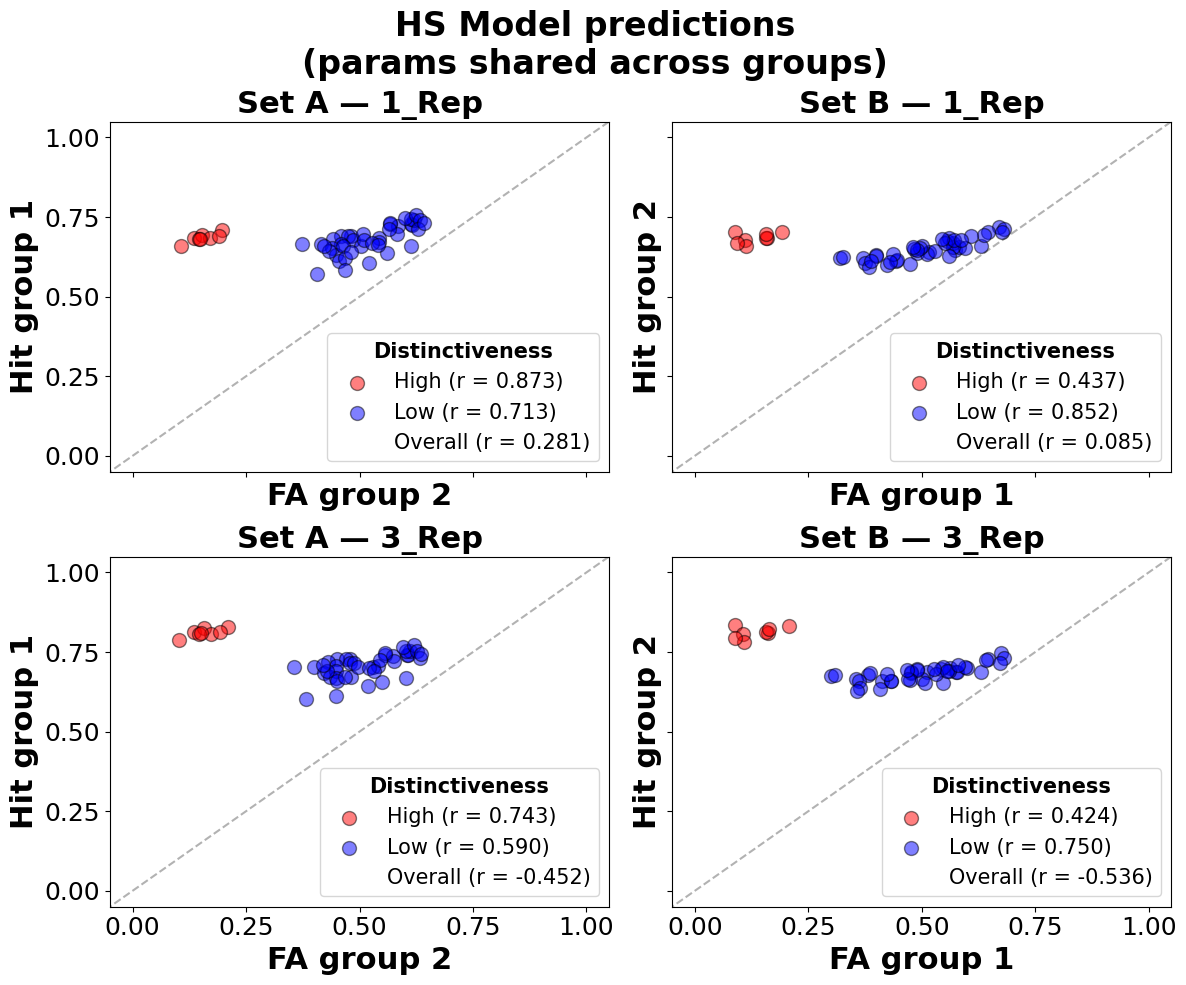

In [140]:
plot_hit_fa_cross_correlations(df_by_item, 'HS_pooled_groups_preds', 'HS Model predictions\n(params shared across groups)')

In [137]:
# Exact correlation values for each panel and condition
get_H_vs_FA_correlations(df_by_item, pred_col='HS_pooled_groups_preds')

Column: HS_pooled_groups_preds

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.87, p = 0.005, n = 8
  Bottom: r = 0.71, p = 0.000, n = 42
  Overall: r = 0.28, p = 0.048, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.44, p = 0.278, n = 8
  Bottom: r = 0.85, p = 0.000, n = 42
  Overall: r = 0.08, p = 0.558, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.74, p = 0.035, n = 8
  Bottom: r = 0.59, p = 0.000, n = 42
  Overall: r = -0.45, p = 0.001, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.42, p = 0.295, n = 8
  Bottom: r = 0.75, p = 0.000, n = 42
  Overall: r = -0.54, p = 0.000, n = 50


### Base model

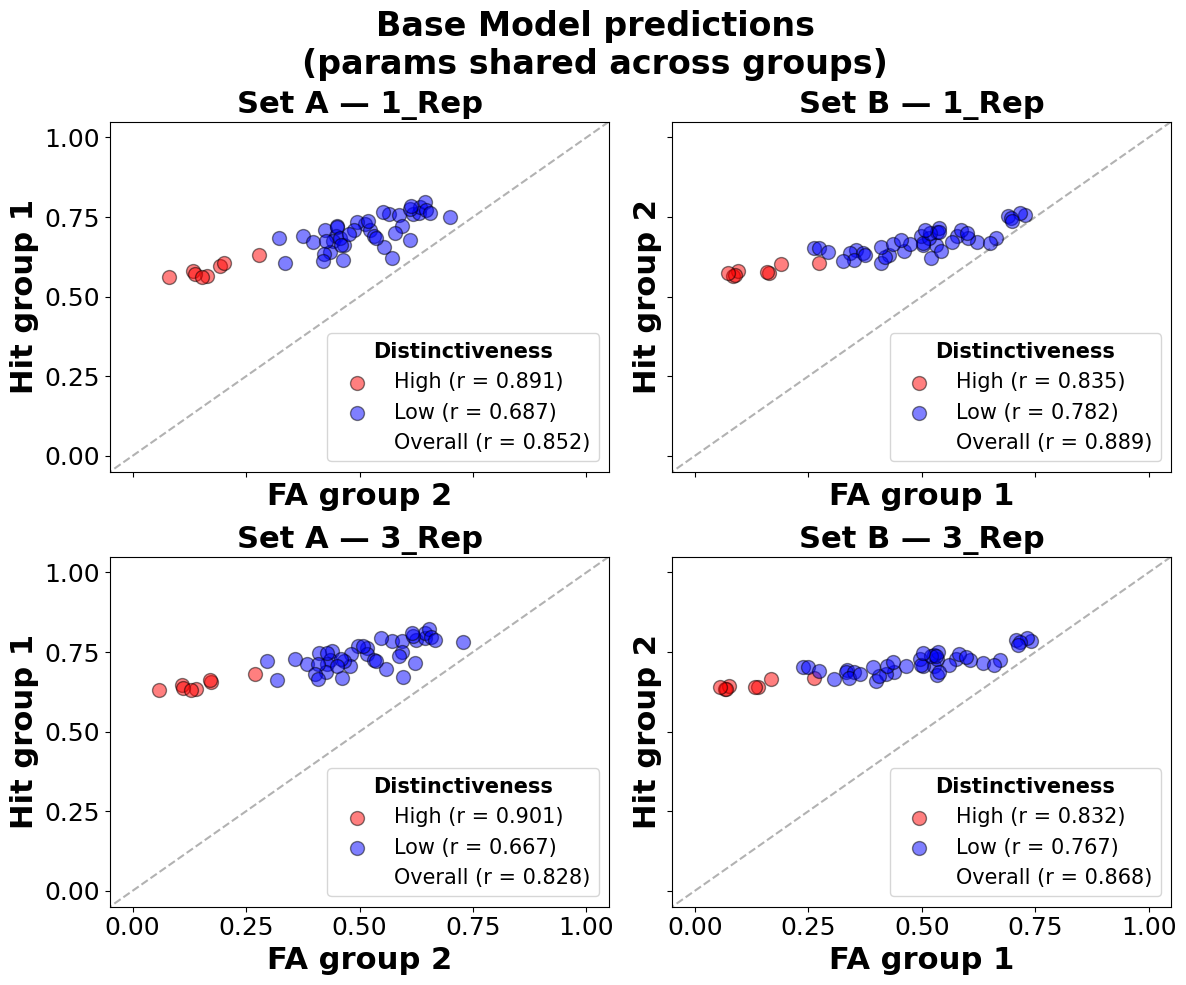

In [141]:
plot_hit_fa_cross_correlations(df_by_item, 'Base_preds', 'Base Model predictions\n(params shared across groups)')

In [142]:
# Exact correlation values for each panel and condition
get_H_vs_FA_correlations(df_by_item, pred_col='Base_preds')

Column: Base_preds

===== CONDITION: 1 Rep =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.89, p = 0.003, n = 8
  Bottom: r = 0.69, p = 0.000, n = 42
  Overall: r = 0.85, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.84, p = 0.010, n = 8
  Bottom: r = 0.78, p = 0.000, n = 42
  Overall: r = 0.89, p = 0.000, n = 50

===== CONDITION: 3 Reps =====

Set A (Group2 FA vs Group1 Hit)
  Top: r = 0.90, p = 0.002, n = 8
  Bottom: r = 0.67, p = 0.000, n = 42
  Overall: r = 0.83, p = 0.000, n = 50

Set B (Group1 FA vs Group2 Hit)
  Top: r = 0.83, p = 0.010, n = 8
  Bottom: r = 0.77, p = 0.000, n = 42
  Overall: r = 0.87, p = 0.000, n = 50


### Simulate models

Predictied hits and false alarms are not noisy at all. So, we want to run many simulations where we will generate random data from the binomial distribution with the number of trials equal to the number of subjects and probability of success = model predicted probability.

In [148]:
MODELS = {
    "HS_pooled_groups_preds": "HS model: 4 params shared across groups",
    "Base_preds": "Base model: 2 params shared across groups",
}
N_ITER = 10_000
SEED = 12345

In [143]:
# Wider format of df_by_item for easier plotting and analysis
df_by_item_wide_simulate = df_by_item.pivot(index=["image_id", "condition", "set", 
                                                   "distinct_type", "distinct_rating", 
                                                   "category_name"],
                                            columns="resp_type")
df_by_item_wide_simulate.columns = [f"{col}_{ans_type.lower()}" for col, ans_type in df_by_item_wide_simulate.columns]
df_by_item_wide_simulate = df_by_item_wide_simulate.reset_index()
df_by_item_wide_simulate

,image_id,condition,set,distinct_type,distinct_rating,category_name,group_fa,group_hit,item_type_fa,item_type_hit,n_subj_fa,n_subj_hit,n_yes_fa,n_yes_hit,prop_yes_fa,prop_yes_hit,HS_pooled_groups_preds_fa,HS_pooled_groups_preds_hit,Base_preds_fa,Base_preds_hit
0,3,1_Rep,B,Bottom,3.17,Andesite,Group1,Group2,Foil,Target,65,61,20,32,0.310606,0.524194,0.516068,0.641501,0.531276,0.662828
1,3,3_Rep,B,Bottom,3.17,Andesite,Group1,Group2,Foil,Target,50,56,14,28,0.284314,0.500000,0.511542,0.688549,0.527527,0.706409
2,4,1_Rep,B,Bottom,3.18,Andesite,Group1,Group2,Foil,Target,65,61,37,34,0.568182,0.556452,0.488979,0.637819,0.461235,0.643111
3,4,3_Rep,B,Bottom,3.18,Andesite,Group1,Group2,Foil,Target,50,56,23,25,0.460784,0.447368,0.477257,0.683902,0.438931,0.686880
4,6,1_Rep,A,Bottom,3.17,Andesite,Group2,Group1,Foil,Target,61,65,34,48,0.556452,0.734848,0.482032,0.691246,0.511663,0.729458
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,471,3_Rep,B,Bottom,2.73,Shale,Group1,Group2,Foil,Target,50,56,21,38,0.421569,0.675439,0.580749,0.709184,0.597645,0.734645
196,472,1_Rep,A,Bottom,2.55,Shale,Group2,Group1,Foil,Target,61,65,22,39,0.362903,0.598485,0.480621,0.639113,0.459293,0.661977
197,472,3_Rep,A,Bottom,2.55,Shale,Group2,Group1,Foil,Target,56,50,14,24,0.254386,0.480392,0.467164,0.672703,0.450899,0.704840
198,476,1_Rep,A,Bottom,2.48,Shale,Group2,Group1,Foil,Target,61,65,32,46,0.524194,0.704545,0.541082,0.661792,0.537338,0.683822


In [146]:
# Calculate pearson correlations for all N_ITER samples instantly
def pearson_rows(x, y):
    return pearsonr(x, y, axis=1).statistic

In [153]:
# Function to run simulations:
# We take predictions from a model and generate noisy data from binomial distributions 
# (based on the predicted probabilities and the number of subjects for hits and false alarms)
# Then we calculate the correlation between hits and false alarms for each simulated dataset
def simulate_H_FA_corrs(model_preds, df=df_by_item_wide_simulate, seed=SEED):
    
    rng = np.random.default_rng(seed)
    
    # Observed data and n of subjects (taken from the same df as the predictions)
    hit_n,   fa_n   = df["n_subj_hit"].to_numpy(),   df["n_subj_fa"].to_numpy()
    hit_obs, fa_obs = df["prop_yes_hit"].to_numpy(), df["prop_yes_fa"].to_numpy()
    
    # Model-predicted probabilities
    hit_p = df[f"{model_preds}_hit"].to_numpy()
    fa_p = df[f"{model_preds}_fa"].to_numpy()
    
    # Simulate observed proportions for every item × condition
    # Shape: (N_ITER, n_items)
    hit_prop = (
        rng.binomial(n=hit_n, p=hit_p, size=(N_ITER, len(df)))
        / hit_n
    )
    
    fa_prop = (
        rng.binomial(n=fa_n, p=fa_p, size=(N_ITER, len(df)))
        / fa_n
    )
    
    distinctiveness_list = ["Bottom", "Top", "Overall"]
    
    results = {}
    
    # Simulate correlations for each condition, set, and distinctiveness group
    for condition in ["1_Rep", "3_Rep"]:
        for set_name in ["A", "B"]:
            
            # Select the relevant items
            panel = (
                (df["condition"] == condition) &
                (df["set"] == set_name)
            )
            
            for distinct_type in distinctiveness_list:
                
                if distinct_type == "Overall":
                    mask = panel.to_numpy()
                else:
                    mask = (
                        panel &
                        (df["distinct_type"] == distinct_type)
                    ).to_numpy()
                
                
                # Observed correlation 
                # (already calculated it before - do it again to save everything together)
                observed_r = pearsonr(
                    fa_obs[mask],
                    hit_obs[mask]
                ).statistic
                
                # Simulated correlations
                simulated_r = pearson_rows(
                    fa_prop[:, mask],
                    hit_prop[:, mask]
                )
                
                # Where does the observed correlation fall
                percentile = np.mean(simulated_r < observed_r)
                
                results[(condition, set_name, distinct_type)] = {
                    "model": model_preds,
                    "condition": condition,
                    "set": set_name,
                    "distinct_type": distinct_type,
                    "n_items": mask.sum(),
                    "observed_r": observed_r,
                    "simulated_r": simulated_r,
                    "simulated_mean": simulated_r.mean(),
                    "simulated_sd": simulated_r.std(),
                    "percentile": percentile,
                    "p_value": 2 * min(percentile, 1 - percentile)
                    }
    
    return results

In [155]:
# Function to plot the results of the simulations
def plot_H_FA_simulations(simulation_results_dict, model_label):
    cond_set_order = [(c, s) for c in ["1_Rep", "3_Rep"] for s in ["A", "B"]]
    distinctiveness_colors = {"Top": "red", "Bottom": "blue", "Overall": "black"}
    
    n_rows = len(cond_set_order)
    n_cols = len(distinctiveness_colors)
    fs = 22  # font size
    fs_axes = 18
    fs_subplot_title = 14
    ax_offset = 0.25

    # squeeze=False - to guarantee that axes is always 2D, even if n_rows or n_cols is 1
    fig, axes = plt.subplots(
        n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows), 
        squeeze=False
    )
    fig.suptitle(model_label, fontsize=fs, y=1.0, fontweight="bold")


    for i, (c, s) in enumerate(cond_set_order):
        for j, (d, col) in enumerate(distinctiveness_colors.items()):
            ax = axes[i, j]
            ax.set_xlim(-1, 1)
            r = simulation_results_dict.get((c, s, d))
            ax.hist(r["simulated_r"], bins=50, color=col, alpha=0.5)
            ax.axvline(r["observed_r"], color="black", lw=2, ls="--")

            # Subplot title: observed r and percentile
            ax.set_title(
                f"observed r={r['observed_r']:.2f}  percentile={r['percentile']:.2f}",
                fontsize=fs_subplot_title,
            )

            # Column titles (only above the top row)
            if i == 0:
                ax.annotate(
                    f"{d}",
                    xy=(0.5, 1+ax_offset),
                    xycoords="axes fraction",
                    ha="center",
                    va="center",
                    fontsize=fs_axes,
                    fontweight="bold",
                )

            # Row labels (only to the left of the first column)
            if j == 0:
                ax.annotate(
                    f"{c[0]} Rep\n Set {s}",
                    xy=(0-ax_offset, 0.5),
                    xycoords="axes fraction",
                    ha="center",
                    va="center",
                    rotation=90,
                    fontsize=fs_axes,
                    fontweight="bold",
                )

    plt.tight_layout()
    plt.show()


===== HS model: 4 params shared across groups =====
                 model condition set distinct_type  n_items  observed_r  simulated_mean  simulated_sd  percentile  p_value
HS_pooled_groups_preds     1_Rep   A        Bottom       42    0.620141        0.335345      0.122214      0.9949   0.0102
HS_pooled_groups_preds     1_Rep   A           Top        8    0.153805        0.105604      0.372966      0.5332   0.9336
HS_pooled_groups_preds     1_Rep   A       Overall       50    0.345857        0.153070      0.116408      0.9541   0.0918
HS_pooled_groups_preds     1_Rep   B        Bottom       42    0.461238        0.338899      0.129587      0.8218   0.3564
HS_pooled_groups_preds     1_Rep   B           Top        8   -0.211159        0.070619      0.377546      0.2478   0.4956
HS_pooled_groups_preds     1_Rep   B       Overall       50    0.337928        0.038578      0.126886      0.9910   0.0180
HS_pooled_groups_preds     3_Rep   A        Bottom       42    0.542998        0.22870

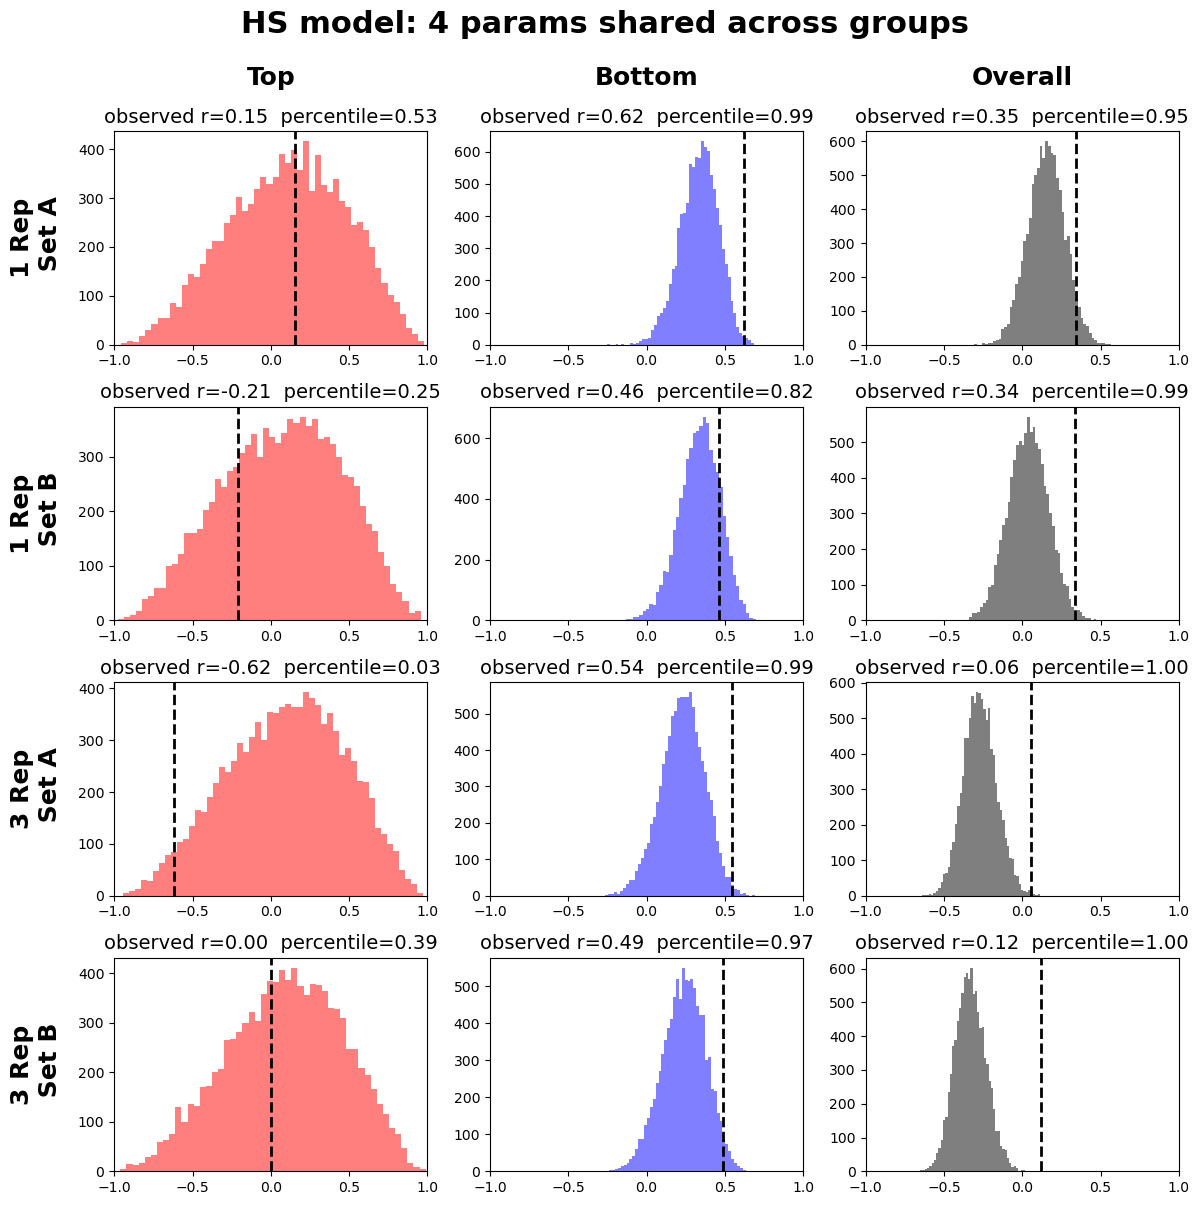


===== Base model: 2 params shared across groups =====
     model condition set distinct_type  n_items  observed_r  simulated_mean  simulated_sd  percentile  p_value
Base_preds     1_Rep   A        Bottom       42    0.620141        0.385539      0.115002      0.9845   0.0310
Base_preds     1_Rep   A           Top        8    0.153805        0.258863      0.340920      0.3539   0.7078
Base_preds     1_Rep   A       Overall       50    0.345857        0.601783      0.076108      0.0011   0.0022
Base_preds     1_Rep   B        Bottom       42    0.461238        0.393956      0.117352      0.7041   0.5918
Base_preds     1_Rep   B           Top        8   -0.211159        0.171462      0.365565      0.1624   0.3248
Base_preds     1_Rep   B       Overall       50    0.337928        0.545871      0.088210      0.0167   0.0334
Base_preds     3_Rep   A        Bottom       42    0.542998        0.325711      0.124635      0.9657   0.0686
Base_preds     3_Rep   A           Top        8   -0.6210

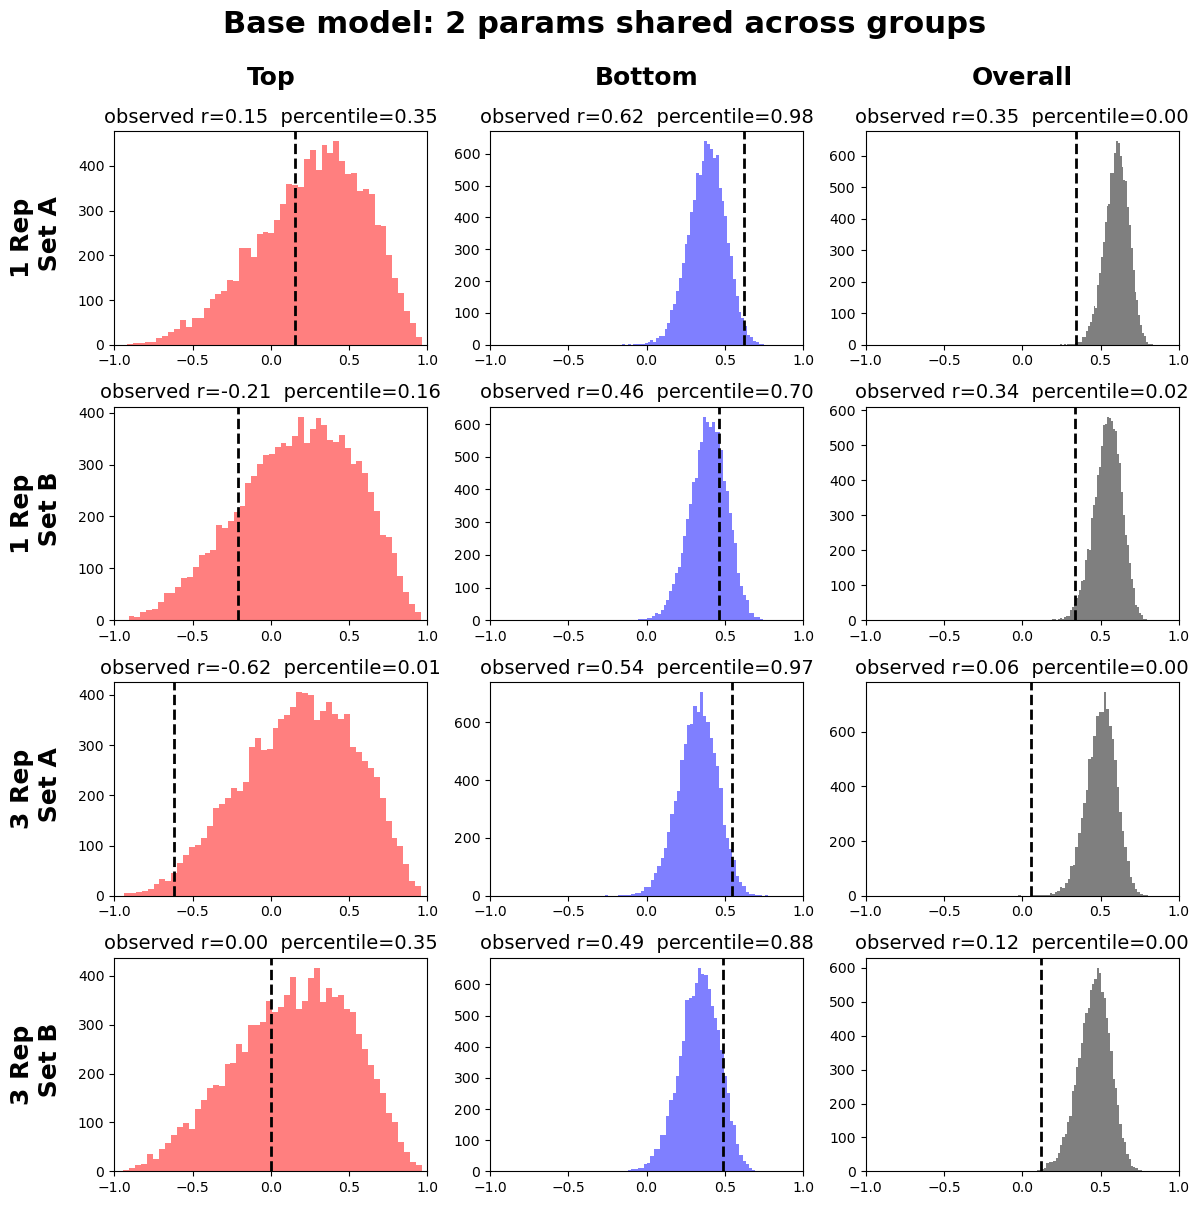

In [156]:
# Run simulations
simulation_H_FA_results = {}

for mod, model_label in MODELS.items():
    
    res = simulate_H_FA_corrs(mod)
    simulation_H_FA_results[mod] = res
    
    # Convert results to DataFrame for printing
    res_df = pd.DataFrame(res.values())
    
    print(f"\n===== {model_label} =====")
    print(res_df.drop(columns="simulated_r").to_string(index=False))
    
    plot_H_FA_simulations(res, model_label)

## Aggregated plot

In [157]:
# Aggregated plot of model predictions and observed data, by set, response type, condition and distinctiveness
def plot_model_summary(df_by_item, fs=20, fs_axes=16, fs_leg=13):
    conditions = ["1_Rep", "3_Rep"]
    sets = ["A", "B"]          # rows
    resp_levels = ["Hit", "FA"]  # columns

    distinct_map = {"Bottom": ("Low", "blue"), "Top": ("High", "red")}
    condition_label_map = {"1_Rep": "1 Rep", "3_Rep": "3 Reps"}
    # model column: (offset from bar center, marker, legend label)
    models = {"HS_pooled_groups_preds": (-0.07, "^", "Pooled model"),
              "Base_preds":             ( 0.07, "o", "Base model")}

    x_pos = np.arange(len(conditions))
    bar_width = 0.35
    bar_offsets = {"Bottom": -bar_width / 2, "Top": bar_width / 2}
    panel_w, panel_h = 7, 5

    # -------- summary: mean observed and predicted per cell --------
    summary = (
        df_by_item
        .groupby(["set", "resp_type", "distinct_type", "condition"], observed=True)
        [["prop_yes"] + list(models)]
        .mean()
    )

    fig, axes = plt.subplots(len(sets), len(resp_levels),
                             figsize=(panel_w * len(resp_levels), panel_h * len(sets)),
                             sharey=True)

    for i, s in enumerate(sets):
        for j, resp in enumerate(resp_levels):
            ax = axes[i, j]

            for distinct, (dist_label, color) in distinct_map.items():
                sub = summary.loc[(s, resp, distinct)].reindex(conditions)
                x = x_pos + bar_offsets[distinct]

                ax.bar(x, sub["prop_yes"], width=bar_width, color=color, alpha=0.5)
                for col, (offset, marker, _) in models.items():
                    ax.scatter(x + offset, sub[col], marker=marker, s=150, color=color,
                               edgecolors="k", linewidths=0.8, zorder=5)

            ax.set_title(f"Set {s} — {resp}", fontsize=fs, fontweight="bold")
            ax.set_xticks(x_pos)
            ax.set_xticklabels([condition_label_map[c] for c in conditions], fontsize=fs_axes)
            ax.set_xlim(-0.6, len(conditions) - 0.4)
            ax.set_ylim(-0.05, 1.05)
            ax.set_yticks(np.arange(0, 1.1, 0.25))
            ax.tick_params(axis="both", labelsize=fs_axes)

    # -------- shared legend --------
    legend_elements = (
        [Patch(facecolor=color, alpha=0.5, label=f"{label} - Observed")
         for label, color in distinct_map.values()]
        + [Line2D([0], [0], marker="None", color="w", label="")]  # spacer
        + [Line2D([0], [0], marker=marker, color="w", markerfacecolor="gray",
                  markeredgecolor="k", markersize=10, label=label)
           for _, marker, label in models.values()]
    )
    leg = fig.legend(handles=legend_elements, loc="center right", bbox_to_anchor=(1.17, 0.5),
                     fontsize=fs_leg, title="Distinctiveness", title_fontsize=fs_leg)
    leg.get_title().set_fontweight("bold")

    fig.text(-0.02, 0.5, 'Proportion "Old"', va="center", rotation="vertical",
             fontsize=fs, fontweight="bold")
    fig.text(0.5, -0.02, "Condition", ha="center", fontsize=fs, fontweight="bold")

    plt.tight_layout()
    plt.show()

In [183]:
# Aggregated plot of model predictions and observed data, by set, response type, condition and distinctiveness
def plot_model_summary(df_by_item, fs=20, fs_axes=16, fs_leg=16):
    conditions = ["1_Rep", "3_Rep"]
    sets = ["A", "B"]          # rows
    resp_levels = ["Hit", "FA"]  # columns

    distinct_map = {"Bottom": ("Low", "blue"), "Top": ("High", "red")}
    condition_label_map = {"1_Rep": "1 Rep", "3_Rep": "3 Reps"}
    # model column: (offset from bar center, marker, legend label)
    models = {"HS_pooled_groups_preds": (-0.07, "^", "HS model"),
              "Base_preds":             ( 0.07, "o", "Base model")}

    x_pos = np.arange(len(conditions))
    bar_width = 0.35
    bar_offsets = {"Bottom": -bar_width / 2, "Top": bar_width / 2}
    panel_w, panel_h = 7, 5

    # -------- summary: mean observed and predicted per cell --------
    summary = (
        df_by_item
        .groupby(["set", "resp_type", "distinct_type", "condition"], observed=True)
        [["prop_yes"] + list(models)]
        .mean()
    )

    fig, axes = plt.subplots(len(sets), len(resp_levels),
                             figsize=(panel_w * len(resp_levels), panel_h * len(sets)),
                             sharey=True)

    for i, s in enumerate(sets):
        for j, resp in enumerate(resp_levels):
            ax = axes[i, j]

            for distinct, (dist_label, color) in distinct_map.items():
                sub = summary.loc[(s, resp, distinct)].reindex(conditions)
                x = x_pos + bar_offsets[distinct]

                ax.bar(x, sub["prop_yes"], width=bar_width, color=color, alpha=0.5)
                for col, (offset, marker, _) in models.items():
                    ax.scatter(x + offset, sub[col], marker=marker, s=150, color=color,
                               edgecolors="k", linewidths=0.8, zorder=5)

            # Column header (top row only)
            if i == 0:
                ax.set_title(resp, fontsize=fs + 6, fontweight="bold", pad=15)
            # Row label (right of the last column only)
            if j == len(resp_levels) - 1:
                ax.annotate(f"Set {s}", xy=(1.02, 0.5), xycoords="axes fraction",
                            rotation=-90, ha="left", va="center",
                            fontsize=fs + 6, fontweight="bold")
            ax.set_xticks(x_pos)
            ax.set_xticklabels([condition_label_map[c] for c in conditions], fontsize=fs_axes)
            ax.set_xlim(-0.6, len(conditions) - 0.4)
            ax.set_ylim(-0.05, 1.05)
            ax.set_yticks(np.arange(0, 1.01, 0.2))
            ax.tick_params(axis="both", labelsize=fs_axes)
            ax.grid(axis="y", linestyle="--", alpha=0.6)
            ax.set_axisbelow(True)  # draw grid behind bars and markers

    # -------- shared legend --------
    legend_elements = (
        [Patch(facecolor=color, alpha=0.5, label=f"{label} - Observed")
         for label, color in distinct_map.values()]
        + [Line2D([0], [0], marker="None", color="w", label="")]  # spacer
        + [Line2D([0], [0], marker=marker, color="w", markerfacecolor="gray",
                  markeredgecolor="k", markersize=10, label=label)
           for _, marker, label in models.values()]
    )
    leg = fig.legend(handles=legend_elements, loc="center left", bbox_to_anchor=(1.0, 0.5),
                    fontsize=fs_leg, title="Distinctiveness", title_fontsize=fs_leg)
    leg.get_title().set_fontweight("bold")

    fig.text(-0.02, 0.5, 'Proportion "Old"', va="center", rotation="vertical",
             fontsize=fs, fontweight="bold")
    fig.text(0.5, -0.02, "Condition", ha="center", fontsize=fs, fontweight="bold")

    plt.tight_layout()
    plt.show()

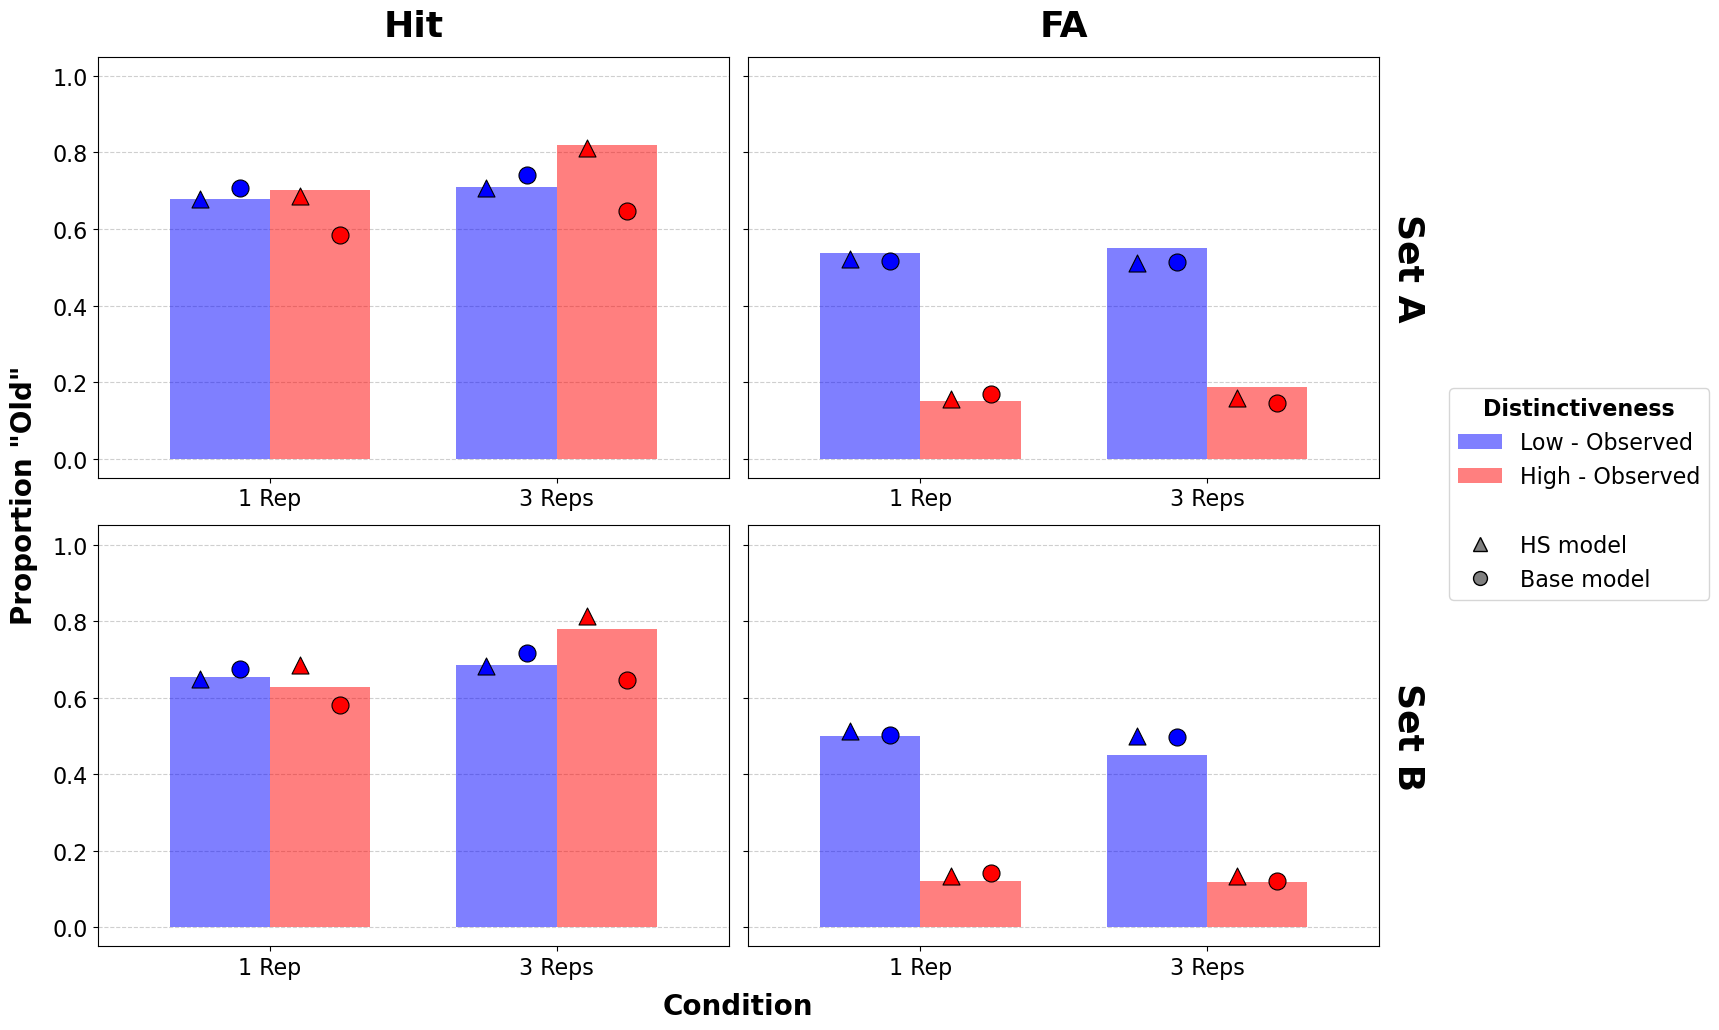

In [184]:
plot_model_summary(df_by_item)

# Model Comparison

In [187]:
def information_criteria(optimization_result, data, models, conditions=("1_Rep", "3_Rep")):
    rows = []
    for model in models:
        for cond in conditions:
            res = optimization_result[model][cond]
            n = (data["condition"] == cond).sum()   # see note on n below
            k = len(res.x)
            nll = res.fun
            rows.append({"model": model, "condition": cond, "k": k, "nll": nll, "n": n,
                         "aic": 2 * k + 2 * nll,
                         "bic": k * np.log(n) + 2 * nll})
    ic = pd.DataFrame(rows)

    # Totals across conditions (conditions were fit independently, so NLL, k and n add up)
    total = ic.groupby("model", as_index=False)[["k", "nll", "n"]].sum()
    total["condition"] = "Total"
    total["aic"] = 2 * total["k"] + 2 * total["nll"]
    total["bic"] = total["k"] * np.log(total["n"]) + 2 * total["nll"]

    ic = pd.concat([ic, total], ignore_index=True)
    ic = ic.sort_values(["condition", "model"]).reset_index(drop=True)
    
    return ic

In [188]:
# AIC & BIC
ic_table = information_criteria(optimization_result, filtered_data_test,
                                models=["HS_pooled_groups_model", "Base_model"])
ic_table.round(2)

,model,condition,k,nll,n,aic,bic
0,Base_model,1_Rep,2,8097.47,12600,16198.94,16213.82
1,HS_pooled_groups_model,1_Rep,4,8053.67,12600,16115.35,16145.11
2,Base_model,3_Rep,2,6648.40,10600,13300.81,13315.34
3,HS_pooled_groups_model,3_Rep,4,6562.67,10600,13133.33,13162.41
4,Base_model,Total,4,14745.87,23200,29499.75,29531.95
5,HS_pooled_groups_model,Total,8,14616.34,23200,29248.68,29313.10


# Save data

In [ ]:
# Save only the variables you actually need
variables_to_save = {

    # Split-half lists
    'split_half_hits_within_dict' : sh_corrs_hits,
    'split_half_fa_within_dict' : sh_corrs_fa,
    'split_half_hits_across_dict' : sh_corrs_hits_across,
    'split_half_fa_across_dict' : sh_corrs_fa_across,

    # Aggregated by item
    'df_by_item': df_by_item,
    'df_by_item_wide': df_by_item_wide,
    
    # Distance matrices
    'dist_mat_gr1': dist_mat_gr1,
    'dist_mat_gr2': dist_mat_gr2,
    
    # Distinctiveness dictionary
    'distinctiveness_image_id': distinctiveness_image_id,
    
    # Model
    'optimization_result': optimization_result,
    'all_params': all_params,
    
    # All data (test and memory phases)
    'data_set': data_set,
    'filtered_data_test': filtered_data_test,
    'filtered_data_memory': filtered_data_memory,

}

with open("Exp2_2conds_analysis.pkl", "wb") as f:
    dill.dump(variables_to_save, f)